In [1]:
import torch
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
print(f"CUDA Version: {torch.version.cuda}")
print(f"GPU Name: {torch.cuda.get_device_name(0)}")

PyTorch Version: 2.5.1+cu121
CUDA Available: True
CUDA Version: 12.1
GPU Name: NVIDIA RTX A4000


In [4]:
# ============================================================
# Step 1 — Environment, Imports, Reproducibility, and Runtime Setup
# Target Architecture: SwinSmall_Mask2Former_SGDW_PixelDecoder_CS
# Target Dataset: Cityscapes
# Optimization Mode: VRAM-Armored Mixed Precision Fine-Tuning
# Target mIoU: > 82.0% (Via LSJ, Dynamic Bounding & Loss Annealing)
# ============================================================

import os
import cv2
import gc
import math
import glob
import time
import random
import warnings
import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Strict CUDA memory behavior to prevent fragmentation on 16GB VRAM
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

# Schedulers & Data Loading
from torch.optim.lr_scheduler import CosineAnnealingLR, LinearLR, SequentialLR
from torch.utils.data import Dataset, DataLoader

# VRAM Optimization Tools (AMP & Checkpointing)
from torch.amp import GradScaler, autocast
from torch.utils.checkpoint import checkpoint 

import albumentations as A
from albumentations.pytorch import ToTensorV2

from tqdm import tqdm
from sklearn.metrics import confusion_matrix

from transformers import Mask2FormerConfig, Mask2FormerForUniversalSegmentation

# --------------------------------------------------
# Cleanup and warning control
# --------------------------------------------------
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

warnings.filterwarnings("ignore", category=UserWarning)

# --------------------------------------------------
# Reproducibility Setup
# --------------------------------------------------
SEED = 42

def set_seed(seed: int = 42, deterministic: bool = False):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    os.environ["PYTHONHASHSEED"] = str(seed)

    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        try:
            torch.use_deterministic_algorithms(True)
        except Exception:
            pass
    else:
        torch.backends.cudnn.deterministic = False
        torch.backends.cudnn.benchmark = True

set_seed(SEED, deterministic=False)
print(f"Seed set to {SEED} (deterministic=False for stable/efficient training)")

def seed_worker(worker_id):
    worker_seed = SEED + worker_id
    np.random.seed(worker_seed)
    random.seed(worker_seed)
    torch.manual_seed(worker_seed)

g = torch.Generator()
g.manual_seed(SEED)

# --------------------------------------------------
# Matplotlib & Seaborn Styling Setup
# --------------------------------------------------
%matplotlib inline
plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 600
plt.rcParams["figure.figsize"] = (8, 5)
sns.set_style("whitegrid")
sns.set_context("talk", font_scale=0.9)

# --------------------------------------------------
# Device & Engine Configuration
# --------------------------------------------------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using Device: {DEVICE}")

if torch.cuda.is_available():
    print(f"GPU Model: {torch.cuda.get_device_name(0)}")
    print(f"CUDA Toolchain Version: {torch.version.cuda}")
    print(f"Total Available GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")

if torch.cuda.is_available():
    try:
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
        print("TF32 matrix operations enabled successfully.")
    except Exception as e:
        print(f"TF32 configuration skipped: {e}")

# --------------------------------------------------
# Strategy Variables for >82% mIoU
# --------------------------------------------------
PHYSICAL_BATCH_SIZE = 2
GRAD_ACCUM_STEPS = 8  
USE_AMP = torch.cuda.is_available()
scaler = GradScaler("cuda" if torch.cuda.is_available() else "cpu", enabled=USE_AMP)
print(f"Mixed Precision Training Enabled: {USE_AMP}")
print(f"Targeting Effective Batch Size: {PHYSICAL_BATCH_SIZE * GRAD_ACCUM_STEPS}")

# --------------------------------------------------
# CENTRALIZED DIRECTORY & PATH MAPPING
# --------------------------------------------------
IMG_ROOT = Path("/home/hrusikesh-nishank/miniconda3/envs/Segmentation/Datasets/leftImg8bit_trainvaltest/leftImg8bit")
MASK_ROOT = Path("/home/hrusikesh-nishank/miniconda3/envs/Segmentation/Datasets/gtFine_trainvaltest/gtFine")

# Final explicit save directory for ONNX models, checkpoints, and training graphs
FINAL_SAVE_DIR = Path("/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS/Results_Export") 
QUAL_VIS_DIR = Path("/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS/training_visuals")

# Local Working Directories anchored strictly to FINAL_SAVE_DIR
CHECKPOINT_DIR = FINAL_SAVE_DIR / "progressive_checkpoints_sgdw_v2_cs"
PLOTS_DIR = FINAL_SAVE_DIR / "training_plots_sgdw_v2_cs"
LOGS_DIR = FINAL_SAVE_DIR / "training_logs_sgdw_v2_cs"
METRICS_DIR = FINAL_SAVE_DIR / "training_metrics_sgdw_v2_cs"

for d in [CHECKPOINT_DIR, PLOTS_DIR, LOGS_DIR, METRICS_DIR, FINAL_SAVE_DIR, QUAL_VIS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# Model Specifications
# --------------------------------------------------
MODEL_NAME = "facebook/mask2former-swin-small-cityscapes-semantic"
MODEL_ALIAS = "Semantically Guided Deformable Window (Pixel Decoder) - Swin-Small"

print(f"\nModel Configuration Linked: {MODEL_ALIAS}")
print(f"Pre-trained Model Base: {MODEL_NAME}")
print(f"Global Analytical Results Save Path Linked: {FINAL_SAVE_DIR.resolve()}")

# --------------------------------------------------
# Runtime Performance Containers & Checkpoint Manager
# --------------------------------------------------
history = {
    "epoch": [],
    "phase": [],
    "train_total_loss": [],
    "train_boundary_loss": [], 
    "train_miou": [],    
    "train_macc": [],    
    "train_aacc": [],    
    "val_total_loss": [],
    "val_miou": [],
    "val_macc": [],
    "val_aacc": [],
    "backbone_lr": [],
    "head_lr": [],
    "sgdw_offset_magnitude": [], 
    "sgdw_dynamic_bound": [],    
    "epoch_time_sec": [],
    "total_training_time_str": [] # Captures format like '2 days, 9:32:15'
}

best_record = {
    "epoch": -1,
    "best_epoch": -1,
    "best_miou": -1.0,
    "best_macc": -1.0,
    "best_aacc": -1.0,
    "best_path": str(CHECKPOINT_DIR / "best_model_sgdw_cs.pt"),
    "latest_path": str(CHECKPOINT_DIR / "latest_model_sgdw_cs.pt")
}

def save_checkpoint(epoch, model, optimizer_backbone, optimizer_head, scaler, scheduler, history_dict, total_time, is_best=False):
    """
    Saves a comprehensive checkpoint containing model state, optimizer states, 
    and the full training history/time. Ensures only two files exist: best and latest.
    """
    state = {
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_backbone_state_dict': optimizer_backbone.state_dict(),
        'optimizer_head_state_dict': optimizer_head.state_dict(),
        'scaler_state_dict': scaler.state_dict(),
        'scheduler_state_dict': scheduler.state_dict() if scheduler else None,
        'history': history_dict,
        'total_training_time': total_time,
        'best_record': best_record
    }
    
    # Always save latest
    torch.save(state, best_record['latest_path'])
    
    # Save best if flagged
    if is_best:
        torch.save(state, best_record['best_path'])
        print(f"\n[Checkpoint] New Best Model Saved! Val mIoU: {best_record['best_miou']*100:.2f}% | Total Time Elapsed: {total_time}")

print("Metrics tracking layers constructed. Global paths centralized. Checkpoint Manager ready. Step 1 sequence completed.")

Seed set to 42 (deterministic=False for stable/efficient training)
Using Device: cuda
GPU Model: NVIDIA RTX A4000
CUDA Toolchain Version: 12.1
Total Available GPU Memory: 15.73 GB
TF32 matrix operations enabled successfully.
Mixed Precision Training Enabled: True
Targeting Effective Batch Size: 16

Model Configuration Linked: Semantically Guided Deformable Window (Pixel Decoder) - Swin-Small
Pre-trained Model Base: facebook/mask2former-swin-small-cityscapes-semantic
Global Analytical Results Save Path Linked: /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS/Results_Export
Metrics tracking layers constructed. Global paths centralized. Checkpoint Manager ready. Step 1 sequence completed.


In [5]:
# ============================================================
# STEP 2: HYPERPARAMETERS, LABEL ENCODING, VISUALIZATION
# Target Architecture: SwinSmall_Mask2Former_SGDW_PixelDecoder_CS
# Target Dataset: Cityscapes
# ============================================================

from pathlib import Path
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick # Added for strict percentage formatting
import seaborn as sns
import pandas as pd
import torch
import torch.nn.functional as F

# Note: Paths (IMG_ROOT, MASK_ROOT, FINAL_SAVE_DIR, QUAL_VIS_DIR) 
# and DEVICE are globally inherited from Step 1.

print(f"Image root inherited: {IMG_ROOT}")
print(f"Mask root inherited : {MASK_ROOT}")
print(f"Visualizations target: {QUAL_VIS_DIR.resolve()}")
print(f"Final export target: {FINAL_SAVE_DIR.resolve()}")

# ------------------------------------------------------------
# CORE TASK SETTINGS (Cityscapes 19-Class Standard)
# ------------------------------------------------------------
CLASSES = 19
IGNORE_INDEX = 255
USE_LABEL_TRAINIDS = True

CLASS_NAMES = [
    "Road", "Sidewalk", "Building", "Wall", "Fence", "Pole",
    "Traffic Light", "Traffic Sign", "Vegetation", "Terrain", "Sky",
    "Person", "Rider", "Car", "Truck", "Bus", "Train", "Motorcycle", "Bicycle"
]

# Standard Cityscapes RGB Color Palette
CITYSCAPES_PALETTE = np.array([
    [128, 64, 128],   # Road
    [244, 35, 232],   # Sidewalk
    [70, 70, 70],     # Building
    [102, 102, 156],  # Wall
    [190, 153, 153],  # Fence
    [153, 153, 153],  # Pole
    [250, 170, 30],   # Traffic Light
    [220, 220, 0],    # Traffic Sign
    [107, 142, 35],   # Vegetation
    [152, 251, 152],  # Terrain
    [70, 130, 180],   # Sky
    [220, 20, 60],    # Person
    [255, 0, 0],      # Rider
    [0, 0, 142],      # Car
    [0, 0, 70],       # Truck
    [0, 60, 100],     # Bus
    [0, 80, 100],     # Train
    [0, 0, 230],      # Motorcycle
    [119, 11, 32]     # Bicycle
], dtype=np.uint8)

# ------------------------------------------------------------
# IMAGE GEOMETRY (Adapted for Cityscapes resolution)
# ------------------------------------------------------------
IMG_H = 512
IMG_W = 1024
VAL_IMG_H = 1024  
VAL_IMG_W = 2048  

# ------------------------------------------------------------
# BATCHING AND EPOCHS (Hardware Optimized for RTX A4000 16GB)
# ------------------------------------------------------------
BATCH_SIZE = 2
GRAD_ACCUM_STEPS = 8    
EPOCHS = 120
USE_EARLY_STOPPING = False  

# ------------------------------------------------------------
# TRIPARTITE SGDW OPTIMIZATION SCHEDULE
# ------------------------------------------------------------
BASE_HEAD_LR = 1e-4        
BACKBONE_LR = 1e-5         
SGDW_OFFSET_LR = 1e-5     # Reduced to prevent offset explosion during init

WARMUP_EPOCHS = 3         
WEIGHT_DECAY = 0.05       
GRAD_CLIP_NORM = 0.01     

print("\n--- SGDW Swin-Small Multi-Rate Fine-Tuning Schedule ---")
print(f"Total Training Epochs: {EPOCHS}")
print(f"Linear Warmup Period  : {WARMUP_EPOCHS} Epochs")
print(f"Decoder Head LR       : {BASE_HEAD_LR}")
print(f"Swin Backbone LR      : {BACKBONE_LR}")
print(f"SGDW Offset Net LR    : {SGDW_OFFSET_LR}")

# ------------------------------------------------------------
# VALIDATION / INFERENCE SETTINGS
# ------------------------------------------------------------
USE_SLIDING_WINDOW_VAL = True
VAL_WINDOW_SIZE = (512, 1024)
VAL_WINDOW_STRIDE = (341, 682)   
USE_FLIP_TTA = True              

# ------------------------------------------------------------
# SCHEDULER / LOSS SETTINGS
# ------------------------------------------------------------
DICE_WEIGHT = 5.0
MASK_WEIGHT = 5.0
CE_WEIGHT = 2.0

USE_BOUNDARY_LOSS = True
BOUNDARY_LOSS_WEIGHT = 0.25 # Increased to 0.25 to aggressively penalize bad geometric offsets

# ------------------------------------------------------------
# 34 -> 19 LABEL MAPPING & ENCODING (Cityscapes Specific)
# ------------------------------------------------------------
mapping_34_to_19 = {
    0: 255, 1: 255, 2: 255, 3: 255, 4: 255, 5: 255, 6: 255,
    7: 0, 8: 1, 9: 255, 10: 255, 11: 2, 12: 3, 13: 4,
    14: 255, 15: 255, 16: 255, 17: 5, 18: 255, 19: 6, 20: 7,
    21: 8, 22: 9, 23: 10, 24: 11, 25: 12, 26: 13, 27: 14,
    28: 15, 29: 255, 30: 255, 31: 16, 32: 17, 33: 18, -1: 255
}

LABEL_LUT = np.full(256, IGNORE_INDEX, dtype=np.uint8)
for k, v in mapping_34_to_19.items():
    if 0 <= k <= 255:
        LABEL_LUT[k] = v

def encode_mask(mask: np.ndarray) -> np.ndarray:
    uniq = np.unique(mask)
    if uniq.max() <= 255 and np.all(np.isin(uniq, list(range(CLASSES)) + [IGNORE_INDEX])):
        return mask.astype(np.uint8)
    encoded = LABEL_LUT[mask.clip(0, 255)]
    return encoded.astype(np.uint8)

def decode_segmap(segmentation_map: np.ndarray) -> np.ndarray:
    h, w = segmentation_map.shape
    rgb = np.zeros((h, w, 3), dtype=np.uint8)
    valid_mask = (segmentation_map >= 0) & (segmentation_map < CLASSES)
    for label, color in enumerate(CITYSCAPES_PALETTE):
        rgb[segmentation_map == label] = color
    rgb[~valid_mask] = np.array([0, 0, 0], dtype=np.uint8)
    return rgb

# ------------------------------------------------------------
# PUBLICATION-READY EVALUATION CURVES
# ------------------------------------------------------------
def plot_training_curves(history_dict, save_path=FINAL_SAVE_DIR):
    """
    Plots Total Loss and metrics curves dynamically.
    Enforces percentage formatting and specific epoch intervals.
    """
    keys_to_extract = ['epoch', 'train_total_loss', 'val_total_loss', 'train_miou', 'val_miou']
    safe_dict = {}
    
    target_len = len(history_dict.get('epoch', []))
    if target_len == 0: return

    for k in keys_to_extract:
        if k in history_dict:
            col = history_dict[k]
            if len(col) > target_len:
                safe_dict[k] = col[:target_len]
            elif len(col) < target_len:
                safe_dict[k] = col + [np.nan] * (target_len - len(col))
            else:
                safe_dict[k] = col
        else:
            safe_dict[k] = [np.nan] * target_len

    df = pd.DataFrame(safe_dict)

    # Filter for cleaner presentation (5-epoch intervals)
    interval_df = df[(df['epoch'] % 5 == 0) | (df['epoch'] == df['epoch'].max())]
    epochs_filtered = interval_df['epoch'].values

    sns.set_theme(style="darkgrid")
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    axes[0].plot(epochs_filtered, interval_df["train_total_loss"], marker='o', label='Train Loss', color='blue', linewidth=2)
    if not interval_df["val_total_loss"].isna().all():
        axes[0].plot(epochs_filtered, interval_df["val_total_loss"], marker='s', label='Validation Loss', color='red', linewidth=2)
    axes[0].set_title('Loss Progress', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Epoch', fontsize=12)
    axes[0].set_ylabel('Loss', fontsize=12)
    
    if epochs_filtered.max() >= WARMUP_EPOCHS:
        axes[0].axvline(x=WARMUP_EPOCHS, color='black', linestyle='--', label='Warmup End')
    axes[0].legend(fontsize=12)

    # Convert mIoU to percentage format
    axes[1].plot(epochs_filtered, interval_df["train_miou"] * 100, marker='o', label='Train mIoU', color='green', linewidth=2)
    if not interval_df["val_miou"].isna().all():
        axes[1].plot(epochs_filtered, interval_df["val_miou"] * 100, marker='s', label='Validation mIoU', color='orange', linewidth=2)
    
    axes[1].set_title('mIoU Progress (5-Epoch Intervals)', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Epoch', fontsize=12)
    axes[1].set_ylabel('mIoU', fontsize=12)
    
    # Strictly format Y-axis to show percentage symbol
    axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=2))
    
    if epochs_filtered.max() >= WARMUP_EPOCHS:
        axes[1].axvline(x=WARMUP_EPOCHS, color='black', linestyle='--', label='Warmup End')
    axes[1].legend(fontsize=12)

    plt.tight_layout()
    
    # Save explicitly to the designated final export directory
    combined_graph_path = save_path / "presentation_metrics_progress_sgdw.png"
    plt.savefig(combined_graph_path, dpi=600, bbox_inches="tight")
    plt.close()

# ------------------------------------------------------------
# QUALITATIVE VISUALIZATION
# ------------------------------------------------------------
def visualize_results(loader, model, epoch, save_path=QUAL_VIS_DIR, max_images=3):
    save_path = Path(save_path)
    save_path.mkdir(parents=True, exist_ok=True)
    model.eval()

    batch = next(iter(loader))
    images, mask_labels, class_labels = batch
    images = images.to(DEVICE)
    _, _, current_h, current_w = images.shape

    with torch.no_grad():
        with torch.autocast(device_type="cuda", enabled=(torch.cuda.is_available() and images.is_cuda)):
            outputs = model(pixel_values=images)
            mask_preds = F.interpolate(outputs.masks_queries_logits, size=(current_h, current_w), mode="bilinear", align_corners=False)
            mask_cls = outputs.class_queries_logits.softmax(dim=-1)[..., :-1]
            semantic_logits = torch.einsum("bqc,bqhw->bchw", mask_cls, mask_preds.sigmoid())
            preds = torch.argmax(semantic_logits, dim=1).cpu().numpy()

    images_np = images.detach().cpu().numpy()
    targets = np.full((len(images_np), current_h, current_w), IGNORE_INDEX, dtype=np.uint8)

    for batch_idx in range(len(class_labels)):
        for inst_idx, class_id in enumerate(class_labels[batch_idx]):
            cls_id = int(class_id.item())
            if cls_id != IGNORE_INDEX and 0 <= cls_id < CLASSES:
                instance_mask = mask_labels[batch_idx][inst_idx].cpu().numpy() == 1
                targets[batch_idx][instance_mask] = cls_id

    n = min(max_images, len(images_np))
    fig, axes = plt.subplots(n, 3, figsize=(15, 5 * n))
    if n == 1: axes = np.expand_dims(axes, axis=0)

    for i in range(n):
        img = np.transpose(images_np[i], (1, 2, 0))
        img = img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
        img = np.clip(img, 0, 1)

        axes[i, 0].imshow(img)
        axes[i, 0].set_title("Input Image")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(decode_segmap(targets[i]))
        axes[i, 1].set_title("Ground Truth")
        axes[i, 1].axis("off")

        axes[i, 2].imshow(decode_segmap(preds[i]))
        axes[i, 2].set_title(f"SGDW Prediction (Epoch {epoch})")
        axes[i, 2].axis("off")

    plt.tight_layout()
    out_file = save_path / f"epoch_{epoch:03d}_comparison.png"
    plt.savefig(out_file, dpi=600, bbox_inches="tight")
    plt.close(fig)

def save_visuals_every_10_epochs(epoch, loader, model, save_path=QUAL_VIS_DIR, max_images=3):
    if epoch % 10 == 0:
        visualize_results(loader, model, epoch, save_path, max_images)

# ------------------------------------------------------------
# QUICK DATA DISCOVERY
# ------------------------------------------------------------
train_imgs = sorted(list(IMG_ROOT.rglob("*_leftImg8bit.png")))
train_masks = sorted(list(MASK_ROOT.rglob("*_gtFine_labelIds.png")))

print(f"Discovered {len(train_imgs)} images and {len(train_masks)} masks.")
print("Step 2 fully configured and optimized for SGDW Architecture.")

Image root inherited: /home/hrusikesh-nishank/miniconda3/envs/Segmentation/Datasets/leftImg8bit_trainvaltest/leftImg8bit
Mask root inherited : /home/hrusikesh-nishank/miniconda3/envs/Segmentation/Datasets/gtFine_trainvaltest/gtFine
Visualizations target: /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS/training_visuals
Final export target: /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS/Results_Export

--- SGDW Swin-Small Multi-Rate Fine-Tuning Schedule ---
Total Training Epochs: 120
Linear Warmup Period  : 3 Epochs
Decoder Head LR       : 0.0001
Swin Backbone LR      : 1e-05
SGDW Offset Net LR    : 1e-05
Discovered 5000 images and 5000 masks.
Step 2 fully configured and optimized for SGDW Architecture.


In [6]:
# ============================================================
# STEP 3: DATASET AND DATALOADERS
# Target Architecture: SwinSmall_Mask2Former_SGDW_PixelDecoder_CS
# Target Dataset: Cityscapes
# Optimized for: Large Scale Jittering (LSJ) & Rare-Class Preservation
# ============================================================

import inspect
import cv2
import torch
from torch.utils.data import Dataset, DataLoader
from pathlib import Path
import numpy as np
import albumentations as A
from albumentations.pytorch import ToTensorV2
import os
import random

# ------------------------------------------------------------
# DATASET DISCOVERY FOR CITYSCAPES
# ------------------------------------------------------------
def get_cityscapes_pairs(split):
    img_split_dir = IMG_ROOT / split
    mask_split_dir = MASK_ROOT / split
    
    all_imgs = sorted(list(img_split_dir.rglob("*_leftImg8bit.png")))
    
    valid_imgs = []
    valid_masks = []
    
    for img_path in all_imgs:
        mask_name = img_path.name.replace("_leftImg8bit.png", "_gtFine_labelIds.png")
        city_name = img_path.parent.name
        mask_path = mask_split_dir / city_name / mask_name
        
        if mask_path.exists():
            valid_imgs.append(img_path)
            valid_masks.append(mask_path)
            
    return valid_imgs, valid_masks

train_img_paths, train_mask_paths = get_cityscapes_pairs("train")
val_img_paths, val_mask_paths = get_cityscapes_pairs("val")

if len(train_img_paths) == 0 or len(val_img_paths) == 0:
    raise FileNotFoundError("Could not find valid Cityscapes image/mask pairs. Please check paths.")

print(f"\n--- Cityscapes Dataset Split ---")
print(f"Training image/mask pairs   : {len(train_img_paths)}")
print(f"Validation image/mask pairs : {len(val_img_paths)}")

# ------------------------------------------------------------
# CITYSCAPES 34 -> 19 CLASS MAPPING
# ------------------------------------------------------------
mapping_34_to_19 = {
    0: 255, 1: 255, 2: 255, 3: 255, 4: 255, 5: 255, 6: 255,
    7: 0, 8: 1, 9: 255, 10: 255, 11: 2, 12: 3, 13: 4,
    14: 255, 15: 255, 16: 255, 17: 5, 18: 255, 19: 6, 20: 7,
    21: 8, 22: 9, 23: 10, 24: 11, 25: 12, 26: 13, 27: 14,
    28: 15, 29: 255, 30: 255, 31: 16, 32: 17, 33: 18, -1: 255
}

LABEL_LUT = np.full(256, IGNORE_INDEX, dtype=np.uint8)
for k, v in mapping_34_to_19.items():
    if 0 <= k <= 255:
        LABEL_LUT[k] = v

def encode_mask(mask: np.ndarray) -> np.ndarray:
    """Fast mapping from 34 IDs to 19 Train IDs."""
    return LABEL_LUT[mask.clip(0, 255)].astype(np.uint8)

# ------------------------------------------------------------
# DATASET
# ------------------------------------------------------------
class CityscapesDataset(Dataset):
    def __init__(self, image_paths, mask_paths, split="train", transform=None, rare_class_ids=None, rare_retry_count=0):
        self.transform = transform
        self.split = split
        self.rare_class_ids = rare_class_ids if rare_class_ids is not None else []
        self.rare_retry_count = rare_retry_count
        self.images = image_paths
        self.masks = mask_paths

    def __len__(self):
        return len(self.images)

    def _contains_rare_class(self, mask):
        if len(self.rare_class_ids) == 0: return False
        unique_ids = np.unique(mask)
        return any(cls_id in unique_ids for cls_id in self.rare_class_ids)

    def __getitem__(self, idx):
        img_path = str(self.images[idx])
        mask_path = str(self.masks[idx])

        image = cv2.imread(img_path, cv2.IMREAD_COLOR)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        
        mask_raw = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if mask_raw is None:
            raise ValueError(f"Failed to read mask: {mask_path}")
            
        mask = encode_mask(mask_raw)

        if self.transform is not None:
            # Aggressive rare class sampling loop for the random cropper
            if self.split == "train" and self.rare_retry_count > 0:
                selected_aug = None
                for _ in range(self.rare_retry_count):
                    augmented = self.transform(image=image, mask=mask)
                    aug_mask = augmented["mask"]
                    aug_mask_np = aug_mask.cpu().numpy() if torch.is_tensor(aug_mask) else aug_mask

                    if self._contains_rare_class(aug_mask_np):
                        selected_aug = augmented
                        break
                    selected_aug = augmented
                augmented = selected_aug
            else:
                augmented = self.transform(image=image, mask=mask)

            image = augmented["image"]
            mask = augmented["mask"]

        if not torch.is_tensor(image):
            image = torch.as_tensor(image).permute(2, 0, 1).float()
        if not torch.is_tensor(mask):
            mask = torch.as_tensor(mask, dtype=torch.long)
        else:
            mask = mask.long()

        # Build standard Mask2Former target format: class labels and binary masks (K, H, W)
        unique_labels = torch.unique(mask)
        unique_labels = unique_labels[unique_labels != IGNORE_INDEX]

        if unique_labels.numel() == 0:
            class_labels = torch.empty((0,), dtype=torch.long)
            mask_labels = torch.empty((0, mask.shape[0], mask.shape[1]), dtype=torch.float32)
        else:
            class_labels = unique_labels.long()
            mask_labels = (mask.unsqueeze(0) == class_labels[:, None, None]).float()

        return image, mask_labels, class_labels

# ------------------------------------------------------------
# AUGMENTATION HELPERS & TRANSFORMS
# ------------------------------------------------------------
def pad_if_needed_tf(min_h, min_w, ignore_index=255):
    sig = inspect.signature(A.PadIfNeeded)
    kwargs = dict(min_height=min_h, min_width=min_w, border_mode=cv2.BORDER_CONSTANT, p=1.0)
    if "fill" in sig.parameters:
        kwargs.update(fill=0, fill_mask=ignore_index)
    else:
        kwargs.update(value=0, mask_value=ignore_index)
    return A.PadIfNeeded(**kwargs)

# CRITICAL FOR >82% mIoU: Large Scale Jittering (-0.5 to 1.5)
train_transform = A.Compose([
    A.RandomScale(scale_limit=(-0.5, 1.5), interpolation=cv2.INTER_LINEAR, p=1.0), 
    pad_if_needed_tf(IMG_H, IMG_W, IGNORE_INDEX),
    A.RandomCrop(height=IMG_H, width=IMG_W, p=1.0),
    A.HorizontalFlip(p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05, p=0.3),
    A.GaussianBlur(blur_limit=(3, 3), p=0.1),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(transpose_mask=True),
])

# Validation transform runs at native resolution
val_transform = A.Compose([
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(transpose_mask=True),
])

# ------------------------------------------------------------
# COLLATE FUNCTION
# ------------------------------------------------------------
def mask2former_collate_fn(batch):
    images = torch.stack([item[0] for item in batch], dim=0)
    mask_labels = [item[1] for item in batch]
    class_labels = [item[2] for item in batch]
    return images, mask_labels, class_labels

# ------------------------------------------------------------
# INITIALIZATION
# ------------------------------------------------------------
USE_RARE_CLASS_AWARE_SAMPLING = True
# Classes critical for maximizing validation mIoU: Wall, Fence, Pole, Traffic Light, Traffic Sign, Rider, Truck, Bus, Train, Motorcycle, Bicycle
RARE_CLASS_IDS = [3, 4, 5, 6, 7, 12, 14, 15, 16, 17, 18]  

rare_retry_count = 8 if USE_RARE_CLASS_AWARE_SAMPLING else 0

train_dataset = CityscapesDataset(
    image_paths=train_img_paths, mask_paths=train_mask_paths, split="train",
    transform=train_transform, rare_class_ids=RARE_CLASS_IDS, rare_retry_count=rare_retry_count
)

val_dataset = CityscapesDataset(
    image_paths=val_img_paths, mask_paths=val_mask_paths, split="val",
    transform=val_transform, rare_class_ids=None, rare_retry_count=0
)

NUM_WORKERS = min(4, os.cpu_count() if os.cpu_count() is not None else 2)
PIN_MEMORY = torch.cuda.is_available()
PERSISTENT_WORKERS = NUM_WORKERS > 0

print(f"\n--- DataLoader Hardware Configuration ---")
print(f"Num workers         : {NUM_WORKERS}")
print(f"Pin memory          : {PIN_MEMORY}")
print(f"Rare retry count    : {rare_retry_count}")

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, drop_last=True,
    collate_fn=mask2former_collate_fn,
    worker_init_fn=seed_worker if "seed_worker" in globals() else None,
    generator=g if "g" in globals() else None,
    persistent_workers=PERSISTENT_WORKERS
)

val_loader = DataLoader(
    val_dataset, batch_size=1, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, drop_last=False,
    collate_fn=mask2former_collate_fn,
    worker_init_fn=seed_worker if "seed_worker" in globals() else None,
    generator=g if "g" in globals() else None,
    persistent_workers=PERSISTENT_WORKERS
)

# ------------------------------------------------------------
# SANITY CHECKS
# ------------------------------------------------------------
train_batch = next(iter(train_loader))
train_images, train_mask_labels, train_class_labels = train_batch

print("\n--- Train Batch Sanity Check ---")
print(f"Images shape              : {train_images.shape} (Targeting {IMG_H}x{IMG_W})")
print(f"Sample 0 num segments     : {train_mask_labels[0].shape[0]}")
print(f"Sample 0 mask tensor shape: {train_mask_labels[0].shape}")

val_batch = next(iter(val_loader))
val_images, _, _ = val_batch

assert train_images.shape[-2:] == (IMG_H, IMG_W), f"Expected train crop {IMG_H}x{IMG_W}, got {train_images.shape[-2:]}"

print(f"Validation images shape   : {val_images.shape} (Native Cityscapes Resolution)")
print("\nStep 3 configured successfully and ready to feed the SGDW model.")


--- Cityscapes Dataset Split ---
Training image/mask pairs   : 2975
Validation image/mask pairs : 500

--- DataLoader Hardware Configuration ---
Num workers         : 4
Pin memory          : True
Rare retry count    : 8

--- Train Batch Sanity Check ---
Images shape              : torch.Size([2, 3, 512, 1024]) (Targeting 512x1024)
Sample 0 num segments     : 12
Sample 0 mask tensor shape: torch.Size([12, 512, 1024])
Validation images shape   : torch.Size([1, 3, 1024, 2048]) (Native Cityscapes Resolution)

Step 3 configured successfully and ready to feed the SGDW model.


In [9]:
# ============================================================
# STEP 4: MODEL, OPTIMIZER, LOSS, MULTI-RATE SCHEDULER
# Target Architecture: SGDW-Enhanced Swin-Small (Pixel Decoder Injection)
# Target Dataset: Cityscapes
# Optimized for: Multi-Scale [1, 2, 3] Dilations, True Semantic Guidance, 
# and Epoch-Annealed Boundary Loss (Strict Bipartite Matching)
# ============================================================

import os
import math
import warnings
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torchvision.ops as ops
from torch.optim.lr_scheduler import CosineAnnealingLR, LinearLR, SequentialLR
from transformers import Mask2FormerConfig, Mask2FormerForUniversalSegmentation

# ------------------------------------------------------------
# SAFETY CHECKS & INHERITANCE
# ------------------------------------------------------------
if "train_loader" not in globals():
    raise NameError("train_loader is not defined. Please run Step 3 first.")

DEVICE = globals().get("DEVICE", torch.device("cuda" if torch.cuda.is_available() else "cpu"))
CLASSES = globals().get("CLASSES", 19)
IGNORE_INDEX = globals().get("IGNORE_INDEX", 255)
CLASS_NAMES = globals().get("CLASS_NAMES", [])
EPOCHS = globals().get("EPOCHS", 120)

HF_TOKEN = os.environ.get("HF_TOKEN", None)
if HF_TOKEN is None:
    warnings.filterwarnings("ignore", message=".*unauthenticated requests to the HF Hub.*")

# ------------------------------------------------------------
# LOAD PRETRAINED BASE MODEL WITH OPTIMIZED CONFIG
# ------------------------------------------------------------
MODEL_NAME = globals().get("MODEL_NAME", "facebook/mask2former-swin-small-cityscapes-semantic")
id2label = {i: CLASS_NAMES[i] for i in range(CLASSES)} if CLASS_NAMES else {}
label2id = {v: k for k, v in id2label.items()}

custom_config = Mask2FormerConfig.from_pretrained(
    MODEL_NAME, 
    id2label=id2label, 
    label2id=label2id,
    ignore_mismatched_sizes=True
)
custom_config.dice_weight = globals().get("DICE_WEIGHT", 5.0)
custom_config.mask_weight = globals().get("MASK_WEIGHT", 5.0)
custom_config.class_weight = globals().get("CE_WEIGHT", 2.0)

load_kwargs = dict(
    pretrained_model_name_or_path=MODEL_NAME,
    config=custom_config,
    ignore_mismatched_sizes=True,
)
if HF_TOKEN is not None: load_kwargs["token"] = HF_TOKEN

model = Mask2FormerForUniversalSegmentation.from_pretrained(**load_kwargs).to(DEVICE)
print(f"Loaded fresh base model: {MODEL_NAME} with optimized Bipartite Config.")

def freeze_norm_layers(module: torch.nn.Module):
    norm_types = (torch.nn.BatchNorm1d, torch.nn.BatchNorm2d, torch.nn.BatchNorm3d, torch.nn.SyncBatchNorm)
    for m in module.modules():
        if isinstance(m, norm_types):
            m.eval()
            for p in m.parameters():
                p.requires_grad = False

# ============================================================
# NOVEL ARCHITECTURE: TRUE SEMANTICALLY GUIDED DEFORMABLE WINDOW
# ============================================================

class SemanticallyGuidedDeformableBlock(nn.Module):
    def __init__(self, in_channels, semantic_channels, out_channels, dilations=[1, 2, 3]):
        super().__init__()
        # Align concatenated channels back to local channel depth
        self.channel_align = nn.Conv2d(in_channels + semantic_channels, in_channels, kernel_size=1)
        self.dilations = dilations
        
        self.offset_convs = nn.ModuleList()
        self.dcns = nn.ModuleList()
        
        for d in dilations:
            # 2 * K * K offsets per dilation level
            self.offset_convs.append(
                nn.Conv2d(in_channels, 2 * 3 * 3, kernel_size=3, padding=d, dilation=d)
            )
            self.dcns.append(
                ops.DeformConv2d(in_channels, out_channels, kernel_size=3, padding=d, dilation=d)
            )
            
        self.norm = nn.BatchNorm2d(out_channels)
        self.act = nn.GELU()
        
        # Dynamic boundary controls initial chaotic gradient explosion
        self.deform_bound = nn.Parameter(torch.tensor(0.05))
        self.last_offset_mag = 0.0

        for m in self.offset_convs:
            nn.init.constant_(m.weight, 0)
            nn.init.constant_(m.bias, 0)

    def forward(self, local_x, semantic_guide):
        B, C, H, W = local_x.shape
        
        # 1. Upsample Stage 4 semantic guide to match local resolution
        semantic_up = F.interpolate(semantic_guide, size=(H, W), mode='bilinear', align_corners=False)
        
        # 2. Fuse semantics with local geometry and align channels
        fused_feat = torch.cat([local_x, semantic_up], dim=1)
        fused_feat = self.channel_align(fused_feat)
        
        out = 0
        total_mag = 0
        
        # 3. Predict offsets and apply multi-scale deformable convolutions
        for offset_conv, dcn in zip(self.offset_convs, self.dcns):
            raw_offset = offset_conv(fused_feat)
            
            # Bound offsets to a fraction of the spatial scale to prevent grid destruction
            bounded_offset = torch.tanh(raw_offset) * self.deform_bound.abs() * 10.0
            total_mag += bounded_offset.detach().abs().mean().item()
            
            out = out + dcn(local_x, bounded_offset)
            
        self.last_offset_mag = total_mag / len(self.dilations)
        return self.act(self.norm(out))

class SGDWEncoderWrapper(nn.Module):
    """
    Intercepts the Mask2Former encoder outputs, retrieves the deepest 4D feature map (Stage 4),
    and injects it backward into the 1/4 and 1/8 resolutions via SGDW blocks 
    before passing them to the Multi-Scale Pixel Decoder.
    """
    def __init__(self, original_encoder):
        super().__init__()
        self.original_encoder = original_encoder
        
        # Swin-Small outputs exactly: 96, 192, 384, 768 channels
        self.sgdw_1_4 = SemanticallyGuidedDeformableBlock(in_channels=96, semantic_channels=768, out_channels=96, dilations=[1, 2, 3])
        self.sgdw_1_8 = SemanticallyGuidedDeformableBlock(in_channels=192, semantic_channels=768, out_channels=192, dilations=[1, 2, 3])

    def forward(self, *args, **kwargs):
        outputs = self.original_encoder(*args, **kwargs)
        
        # Extract the 4D feature maps (B, C, H, W)
        # [0]: 96 (1/4), [1]: 192 (1/8), [2]: 384 (1/16), [3]: 768 (1/32)
        feature_maps = list(outputs.feature_maps)
        
        # Deepest feature map serves as explicit semantic guide
        semantic_guide = feature_maps[-1] 
        
        # Apply Multi-Scale SGDW
        feature_maps[0] = self.sgdw_1_4(feature_maps[0], semantic_guide)
        feature_maps[1] = self.sgdw_1_8(feature_maps[1], semantic_guide)
        
        # Safely replace the feature maps in the output object
        outputs.feature_maps = tuple(feature_maps)
        return outputs

    def get_avg_offset_magnitude(self):
        mags = [self.sgdw_1_4.last_offset_mag, self.sgdw_1_8.last_offset_mag]
        return sum(mags) / len(mags)

    def get_avg_dynamic_bound(self):
        bounds = [self.sgdw_1_4.deform_bound.abs().item(), self.sgdw_1_8.deform_bound.abs().item()]
        return sum(bounds) / len(bounds)

class SGDWMasterWrapper(nn.Module):
    def __init__(self, base_model):
        super().__init__()
        self.base_model = base_model
        
        # Surgically replace the HF internal encoder with our interceptor
        original_encoder = self.base_model.model.pixel_level_module.encoder
        self.base_model.model.pixel_level_module.encoder = SGDWEncoderWrapper(original_encoder)
        
        if hasattr(self.base_model.model.pixel_level_module.encoder.original_encoder, "gradient_checkpointing"):
            self.base_model.model.pixel_level_module.encoder.original_encoder.gradient_checkpointing = True

    def forward(self, *args, **kwargs):
        return self.base_model(*args, **kwargs)

    def get_avg_offset_magnitude(self):
        return self.base_model.model.pixel_level_module.encoder.get_avg_offset_magnitude()

    def get_avg_dynamic_bound(self):
        return self.base_model.model.pixel_level_module.encoder.get_avg_dynamic_bound()

model = SGDWMasterWrapper(model).to(DEVICE)
print("\nUnified Multi-Scale SGDW Architecture mapped to Pixel Decoder pipeline successfully.")

# ------------------------------------------------------------
# LOSS FORMULATION (Strict Native Bipartite + Annealed Boundary)
# ------------------------------------------------------------
def compute_boundary_map(targets: torch.Tensor, ignore_index: int = 255) -> torch.Tensor:
    boundary = torch.zeros_like(targets, dtype=torch.bool)
    valid = (targets != ignore_index)
    boundary[:, :, 1:] |= ((targets[:, :, 1:] != targets[:, :, :-1]) & valid[:, :, 1:] & valid[:, :, :-1])
    boundary[:, 1:, :] |= ((targets[:, 1:, :] != targets[:, :-1, :]) & valid[:, 1:, :] & valid[:, :-1, :])
    return boundary.unsqueeze(1).float()

def compute_soft_boundary_map(semantic_logits: torch.Tensor) -> torch.Tensor:
    probs = F.softmax(semantic_logits.float(), dim=1)
    B, C, H, W = probs.shape
    boundary = torch.zeros((B, 1, H, W), device=probs.device, dtype=probs.dtype)
    boundary[:, :, :, 1:] += torch.abs(probs[:, :, :, 1:] - probs[:, :, :, :-1]).mean(dim=1, keepdim=True)
    boundary[:, :, 1:, :] += torch.abs(probs[:, :, 1:, :] - probs[:, :, :-1, :]).mean(dim=1, keepdim=True)
    return boundary.clamp(min=0.0, max=1.0)

def compute_boundary_loss(semantic_logits: torch.Tensor, dense_targets: torch.Tensor, ignore_index: int = 255) -> torch.Tensor:
    with torch.no_grad(): target_boundary = compute_boundary_map(dense_targets, ignore_index=ignore_index)
    pred_boundary = compute_soft_boundary_map(semantic_logits)
    return F.smooth_l1_loss(pred_boundary, target_boundary)

def compute_hybrid_loss(outputs, dense_targets, current_epoch, max_epochs=120):
    native_loss = outputs.loss if outputs.loss is not None else torch.tensor(0.0, device=dense_targets.device)
    boundary_loss = torch.tensor(0.0, device=dense_targets.device)

    base_weight = globals().get("BOUNDARY_LOSS_WEIGHT", 0.25)
    decay_factor = max(0.0, 1.0 - (current_epoch / (max_epochs * 0.75)))
    current_boundary_weight = base_weight * decay_factor

    if current_boundary_weight > 0.0:
        H, W = dense_targets.shape[1], dense_targets.shape[2]
        mask_preds = F.interpolate(outputs.masks_queries_logits, size=(H, W), mode="bilinear", align_corners=False)
        mask_cls = F.softmax(outputs.class_queries_logits, dim=-1)[..., :-1]
        semantic_logits = torch.einsum("bqc,bqhw->bchw", mask_cls, mask_preds.sigmoid())
        boundary_loss = compute_boundary_loss(semantic_logits, dense_targets, ignore_index=IGNORE_INDEX)
        
        total_loss = native_loss + (current_boundary_weight * boundary_loss)
    else:
        total_loss = native_loss

    loss_dict = {
        "native_loss": float(native_loss.detach().item()) if isinstance(native_loss, torch.Tensor) else 0.0,
        "boundary_loss": float(boundary_loss.detach().item()) if isinstance(boundary_loss, torch.Tensor) else 0.0,
        "total_loss": float(total_loss.detach().item())
    }
    return total_loss, loss_dict

# ------------------------------------------------------------
# QUADRIPARTITE MULTI-RATE OPTIMIZER CONFIGURATION
# ------------------------------------------------------------
def configure_continuous_training(model):
    print("\n--- Applying SGDW Quadripartite Fine-Tuning ---")
    
    for p in model.parameters(): p.requires_grad = True
    if globals().get("FREEZE_BATCHNORM_STATS", True): freeze_norm_layers(model)
        
    deform_bound_params, sgdw_params, backbone_params, head_params = [], [], [], []

    for n, p in model.named_parameters():
        if not p.requires_grad: continue
        
        # Isolate parameters accurately based on new wrapper names
        if "deform_bound" in n: deform_bound_params.append(p)
        elif "sgdw" in n or "channel_align" in n or "offset_convs" in n or "dcns" in n: sgdw_params.append(p)
        elif "base_model" in n and "encoder.original_encoder" in n: backbone_params.append(p)
        else: head_params.append(p)

    param_groups = []
    if len(backbone_params) > 0: param_groups.append({"params": backbone_params, "lr": globals().get("BACKBONE_LR", 1e-5)})
    if len(head_params) > 0: param_groups.append({"params": head_params, "lr": globals().get("BASE_HEAD_LR", 1e-4)})
    if len(sgdw_params) > 0: param_groups.append({"params": sgdw_params, "lr": globals().get("SGDW_OFFSET_LR", 1e-5)})
    if len(deform_bound_params) > 0: param_groups.append({"params": deform_bound_params, "lr": 1e-3})

    return optim.AdamW(param_groups, weight_decay=globals().get("WEIGHT_DECAY", 0.05), betas=(0.9, 0.999), eps=1e-8)

# ------------------------------------------------------------
# SCHEDULER: COSINE ANNEALING WITH LINEAR WARMUP
# ------------------------------------------------------------
def build_cosine_warmup_scheduler(optimizer, warmup_steps, total_steps):
    if warmup_steps >= total_steps:
        warmup_steps = max(1, total_steps - 1)
        
    warmup_scheduler = LinearLR(optimizer, start_factor=0.01, end_factor=1.0, total_iters=warmup_steps)
    cosine_scheduler = CosineAnnealingLR(optimizer, T_max=(total_steps - warmup_steps), eta_min=1e-7)
    return SequentialLR(optimizer, schedulers=[warmup_scheduler, cosine_scheduler], milestones=[warmup_steps])

# ------------------------------------------------------------
# SYSTEM INITIALIZATION 
# ------------------------------------------------------------
current_phase = "SGDW Unified Training (Strict Native Loss + Dynamic Bound)"

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

optimizer = configure_continuous_training(model)

steps_per_epoch = math.ceil(len(train_loader) / globals().get("GRAD_ACCUM_STEPS", 8))
total_update_steps = steps_per_epoch * EPOCHS
warmup_steps = steps_per_epoch * globals().get("WARMUP_EPOCHS", 3)

scheduler = build_cosine_warmup_scheduler(optimizer, warmup_steps, total_update_steps)

print(f"Total parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")
print("\nOptimizer & Scheduler Initialized successfully.")
print(f"Steps/epoch          : {steps_per_epoch}")
print(f"Warmup steps         : {warmup_steps}")
print(f"Total update steps   : {total_update_steps}")

print("\nStep 4 configured successfully. Ready for the final training execution.")

Loading weights:   0%|          | 0/782 [00:00<?, ?it/s]

Loaded fresh base model: facebook/mask2former-swin-small-cityscapes-semantic with optimized Bipartite Config.

Unified Multi-Scale SGDW Architecture mapped to Pixel Decoder pipeline successfully.

--- Applying SGDW Quadripartite Fine-Tuning ---
Total parameters     : 70,377,100
Trainable parameters : 70,377,100

Optimizer & Scheduler Initialized successfully.
Steps/epoch          : 186
Warmup steps         : 558
Total update steps   : 22320

Step 4 configured successfully. Ready for the final training execution.


In [10]:
# ============================================================
# STEP 5: TRAINING LOOP (CRASH-RESILIENT & TTA ENABLED)
# Target Architecture: SGDW-Enhanced Swin-Small (Pixel Decoder)
# Target Dataset: Cityscapes
# Optimized for: Dynamic Bound Tracking, Epoch-Annealed Loss, 
# TTA Inference, and VRAM-Safe Bipartite Matching
# ============================================================

import os
import gc
import math
import time
from datetime import timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm import tqdm

# ------------------------------------------------------------
# SAFETY CHECKS & PATH INHERITANCE
# ------------------------------------------------------------
required_globals = [
    "model", "train_loader", "val_loader", "optimizer", "scheduler",
    "CHECKPOINT_DIR", "METRICS_DIR", "DEVICE", 
    "CLASSES", "IGNORE_INDEX", "GRAD_ACCUM_STEPS", "EPOCHS", 
    "FINAL_SAVE_DIR", "QUAL_VIS_DIR", "scaler", "plot_training_curves"
]
missing = [k for k in required_globals if k not in globals()]
if missing:
    print(f"Warning: Missing globals {missing}. Relying on fallback defaults where possible.")

DEVICE = globals().get("DEVICE", torch.device("cuda" if torch.cuda.is_available() else "cpu"))
USE_AMP = globals().get("USE_AMP", torch.cuda.is_available())
GRAD_CLIP_NORM = globals().get("GRAD_CLIP_NORM", 0.01)

MIN_DELTA_MIOU = 0.001
EPOCHS = globals().get("EPOCHS", 120)

# ------------------------------------------------------------
# TEST-TIME AUGMENTATION (TTA) INFERENCE 
# ------------------------------------------------------------
def multi_scale_tta_inference(model, image, scales=[0.75, 1.0, 1.25], num_classes=19):
    B, C, H, W = image.shape
    final_logits = torch.zeros((B, num_classes, H, W), device=image.device, dtype=torch.float32)
    
    model.eval()
    for scale in scales:
        sH, sW = int(H * scale), int(W * scale)
        sH, sW = (sH // 32) * 32, (sW // 32) * 32 
        
        scaled_img = F.interpolate(image, size=(sH, sW), mode='bilinear', align_corners=False)
        
        with torch.no_grad():
            with torch.autocast(device_type="cuda", enabled=USE_AMP):
                outputs = model(pixel_values=scaled_img)
                mask_preds = F.interpolate(outputs.masks_queries_logits, size=(H, W), mode="bilinear", align_corners=False)
                mask_cls = F.softmax(outputs.class_queries_logits, dim=-1)[..., :-1]
                logits = torch.einsum("bqc,bqhw->bchw", mask_cls, mask_preds.sigmoid())
                final_logits += logits.float()
                
        flipped_img = torch.flip(scaled_img, dims=[3])
        with torch.no_grad():
            with torch.autocast(device_type="cuda", enabled=USE_AMP):
                outputs = model(pixel_values=flipped_img)
                mask_preds = F.interpolate(outputs.masks_queries_logits, size=(H, W), mode="bilinear", align_corners=False)
                mask_cls = F.softmax(outputs.class_queries_logits, dim=-1)[..., :-1]
                flip_logits = torch.einsum("bqc,bqhw->bchw", mask_cls, mask_preds.sigmoid())
                final_logits += torch.flip(flip_logits, dims=[3]).float()
                
    return final_logits / (len(scales) * 2)

# ------------------------------------------------------------
# METRICS HELPERS
# ------------------------------------------------------------
def build_semantic_targets(mask_labels, class_labels, image_size, ignore_index=255):
    H, W = image_size
    batch_size = len(mask_labels)
    device = mask_labels[0].device if len(mask_labels) > 0 else DEVICE
    targets = torch.full((batch_size, H, W), fill_value=ignore_index, dtype=torch.long, device=device)
    for b in range(batch_size):
        if class_labels[b].numel() == 0: continue
        for inst_idx, cls_id in enumerate(class_labels[b]):
            cls_id = int(cls_id.item())
            if cls_id == ignore_index: continue
            targets[b][mask_labels[b][inst_idx] > 0.5] = cls_id
    return targets

def compute_metrics(conf_matrix: np.ndarray):
    tp = np.diag(conf_matrix)
    fp = conf_matrix.sum(axis=0) - tp
    fn = conf_matrix.sum(axis=1) - tp
    total_valid = conf_matrix.sum()
    aAcc = np.sum(tp) / (total_valid + 1e-10)
    iou_per_class = tp / (tp + fp + fn + 1e-10)
    mIoU = np.nanmean(iou_per_class)
    class_total = tp + fn
    acc_per_class = tp / (class_total + 1e-10)
    mAcc = np.nanmean(acc_per_class)
    return {"mIoU": float(mIoU), "aAcc": float(aAcc), "mAcc": float(mAcc), "iou_per_class": iou_per_class.tolist(), "acc_per_class": acc_per_class.tolist()}

def fast_confusion_matrix(y_true: np.ndarray, y_pred: np.ndarray, num_classes: int) -> np.ndarray:
    idx = num_classes * y_true + y_pred
    return np.bincount(idx, minlength=num_classes * num_classes).reshape(num_classes, num_classes)

def get_lr_snapshot(optimizer):
    # Retrieve explicitly separated parameter groups
    lrs = [pg["lr"] for pg in optimizer.param_groups]
    return lrs[0], lrs[1] if len(lrs) > 1 else lrs[0]

# ------------------------------------------------------------
# CRASH RECOVERY PROTOCOL
# ------------------------------------------------------------
start_epoch = 1
global_update_step = 0
best_conf_matrix = None
best_metrics = None
training_start_time = time.time()
cumulative_training_time_sec = 0.0 
current_phase = "SGDW Unified Multi-Rate Training"

expected_keys = [
    "epoch", "phase", "train_total_loss", "train_miou", "val_total_loss", 
    "val_miou", "val_macc", "val_aacc", "backbone_lr", "head_lr", 
    "epoch_time_sec", "sgdw_offset_magnitude", "sgdw_dynamic_bound"
]

latest_ckpt_path = os.path.join(CHECKPOINT_DIR, "latest_model_sgdw_cs.pt")

if os.path.exists(latest_ckpt_path):
    print(f"\n[*] CRASH RECOVERY TRIGGERED: Found checkpoint at {latest_ckpt_path}")
    try:
        checkpoint = torch.load(latest_ckpt_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(checkpoint['model_state_dict'])
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
        
        start_epoch = checkpoint['epoch'] + 1
        global_update_step = checkpoint['global_update_step']
        best_record = checkpoint['best_record']
        history = checkpoint['history']
        cumulative_training_time_sec = checkpoint.get('cumulative_training_time_sec', 0.0)

        for key in expected_keys:
            if key not in history:
                history[key] = [np.nan] * (start_epoch - 1)

        target_len = start_epoch - 1
        for key in expected_keys:
            if len(history[key]) > target_len:
                history[key] = history[key][:target_len]
            elif len(history[key]) < target_len:
                history[key].extend([np.nan] * (target_len - len(history[key])))
            
        print(f"[*] History sanitized and synchronized. Resuming from Epoch {start_epoch}.")
    except Exception as e:
        print(f"[!] Warning: Failed to load checkpoint cleanly. Starting from scratch. Error: {e}")
        history = {k: [] for k in expected_keys}
        best_record = {"epoch": -1, "best_epoch": -1, "best_miou": -1.0, "best_macc": -1.0, "best_aacc": -1.0, "best_path": str(CHECKPOINT_DIR / "best_model_sgdw_cs.pt")}
        cumulative_training_time_sec = 0.0
else:
    history = globals().get("history", {k: [] for k in expected_keys})
    best_record = globals().get("best_record", {"epoch": -1, "best_epoch": -1, "best_miou": -1.0, "best_macc": -1.0, "best_aacc": -1.0, "best_path": str(CHECKPOINT_DIR / "best_model_sgdw_cs.pt")})
    cumulative_training_time_sec = 0.0

print(f"\n--- Launching SGDW Pipeline ---")
print(f"Target Epochs: {EPOCHS} (Currently at {start_epoch})")
print(f"TTA Enabled for Validation: YES")

# ------------------------------------------------------------
# MAIN LOOP
# ------------------------------------------------------------
for epoch in range(start_epoch, EPOCHS + 1):
    epoch_start_time = time.time()

    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

    # Train
    model.train()
    optimizer.zero_grad(set_to_none=True)

    train_total_loss_sum = 0.0
    train_batches = 0
    train_conf_matrix = np.zeros((CLASSES, CLASSES), dtype=np.int64)
    train_pbar = tqdm(train_loader, total=len(train_loader), desc=f"Epoch {epoch}/{EPOCHS} [Train]", leave=False)

    for step, (images, mask_labels, class_labels) in enumerate(train_pbar, start=1):
        images = images.to(DEVICE, non_blocking=True)
        mask_labels = [m.to(DEVICE, non_blocking=True) for m in mask_labels]
        class_labels = [c.to(DEVICE, non_blocking=True) for c in class_labels]

        _, _, curr_h, curr_w = images.shape
        dense_targets = build_semantic_targets(mask_labels, class_labels, (curr_h, curr_w), IGNORE_INDEX)

        with torch.autocast(device_type="cuda", enabled=USE_AMP):
            outputs = model(pixel_values=images, mask_labels=mask_labels, class_labels=class_labels)
            
            # Pass epoch for Boundary Loss Annealing
            total_loss, loss_dict = compute_hybrid_loss(outputs, dense_targets, current_epoch=epoch, max_epochs=EPOCHS)
            loss = total_loss / GRAD_ACCUM_STEPS

        scaler.scale(loss).backward()

        train_total_loss_sum += loss_dict["total_loss"]
        train_batches += 1

        with torch.no_grad():
            mask_preds = F.interpolate(outputs.masks_queries_logits, size=(curr_h, curr_w), mode="bilinear", align_corners=False)
            mask_cls = F.softmax(outputs.class_queries_logits, dim=-1)[..., :-1]
            semantic_logits = torch.einsum("bqc,bqhw->bchw", mask_cls, mask_preds.sigmoid())
            
            preds = torch.argmax(semantic_logits, dim=1)
            preds_np = preds.detach().cpu().numpy().astype(np.int64)
            targets_np = dense_targets.detach().cpu().numpy().astype(np.int64)
            valid = (targets_np != IGNORE_INDEX)
            if valid.any():
                train_conf_matrix += fast_confusion_matrix(targets_np[valid], preds_np[valid], CLASSES)

        if (step % GRAD_ACCUM_STEPS == 0) or (step == len(train_loader)):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()
            global_update_step += 1

        lr_backbone, lr_head = get_lr_snapshot(optimizer)
        current_offset_mag = model.get_avg_offset_magnitude()
        current_dynamic_bound = model.get_avg_dynamic_bound()
        
        train_pbar.set_postfix(
            loss=f"{train_total_loss_sum / max(1, train_batches):.4f}",
            bound=f"{current_dynamic_bound:.4f}",
            offset=f"{current_offset_mag:.4f}"
        )

    train_metrics = compute_metrics(train_conf_matrix)
    train_total_loss = train_total_loss_sum / max(1, train_batches)
    avg_offset_magnitude = model.get_avg_offset_magnitude()
    avg_dynamic_bound = model.get_avg_dynamic_bound()

    # Validation (WITH TTA)
    model.eval()
    val_total_batches = 0
    val_total_loss_sum = 0.0
    val_conf_matrix = np.zeros((CLASSES, CLASSES), dtype=np.int64)
    val_pbar = tqdm(val_loader, total=len(val_loader), desc=f"Epoch {epoch}/{EPOCHS} [Val (TTA)]", leave=False)

    with torch.no_grad():
        for images, mask_labels, class_labels in val_pbar:
            images = images.to(DEVICE, non_blocking=True)
            _, _, val_h, val_w = images.shape
            
            mask_labels = [m.to(DEVICE, non_blocking=True) for m in mask_labels]
            class_labels = [c.to(DEVICE, non_blocking=True) for c in class_labels]
            dense_targets = build_semantic_targets(mask_labels, class_labels, (val_h, val_w), IGNORE_INDEX)

            # TTA Inference
            semantic_logits = multi_scale_tta_inference(model, images, scales=[0.75, 1.0, 1.25], num_classes=CLASSES)
            
            # Validation Loss Evaluation
            ce_loss = F.cross_entropy(semantic_logits, dense_targets, ignore_index=IGNORE_INDEX)
            val_total_loss_sum += ce_loss.item()

            val_total_batches += 1

            preds = torch.argmax(semantic_logits, dim=1)
            preds_np = preds.detach().cpu().numpy().astype(np.int64)
            targets_np = dense_targets.detach().cpu().numpy().astype(np.int64)
            valid = (targets_np != IGNORE_INDEX)
            if valid.any():
                val_conf_matrix += fast_confusion_matrix(targets_np[valid], preds_np[valid], CLASSES)
            val_metrics_preview = compute_metrics(val_conf_matrix)
            val_pbar.set_postfix(mIoU=f"{val_metrics_preview['mIoU'] * 100:.2f}%")

    val_metrics = compute_metrics(val_conf_matrix)
    val_total_loss = val_total_loss_sum / max(1, val_total_batches)

    # ------------------------------------------------------------
    # EPOCH STEP UPDATES & TIME TRACKING LOGIC
    # ------------------------------------------------------------
    epoch_time = time.time() - epoch_start_time
    cumulative_training_time_sec += epoch_time  
    
    elapsed_this_session = time.time() - training_start_time
    epochs_run_this_session = epoch - start_epoch + 1
    eta_str = str(timedelta(seconds=int((elapsed_this_session / epochs_run_this_session) * (EPOCHS - epoch))))
    
    lr_backbone, lr_head = get_lr_snapshot(optimizer)

    history["epoch"].append(epoch)
    history["phase"].append(current_phase)
    history["train_total_loss"].append(train_total_loss)
    history["train_miou"].append(train_metrics["mIoU"])
    history["val_total_loss"].append(val_total_loss)
    history["val_miou"].append(val_metrics["mIoU"])
    history["val_macc"].append(val_metrics["mAcc"])
    history["val_aacc"].append(val_metrics["aAcc"])
    history["backbone_lr"].append(lr_backbone)
    history["head_lr"].append(lr_head)
    history["epoch_time_sec"].append(epoch_time)
    history["sgdw_offset_magnitude"].append(avg_offset_magnitude)
    history["sgdw_dynamic_bound"].append(avg_dynamic_bound)

    print(
        f"\nEpoch {epoch}/{EPOCHS} | Time: {epoch_time:.2f}s | ETA: {eta_str}\n"
        f"Train Loss: {train_total_loss:.4f} | Train mIoU: {train_metrics['mIoU']*100:.2f}%\n"
        f"Val Loss:   {val_total_loss:.4f} | Val mIoU:   {val_metrics['mIoU']*100:.2f}% | Val aAcc:   {val_metrics['aAcc']*100:.2f}%\n"
        f"LR Head: {lr_head:.2e} | SGDW Bound: {avg_dynamic_bound:.4f} | SGDW Offset Mag: {avg_offset_magnitude:.4f}"
    )

    # ------------------------------------------------------------
    # STRICT 2-CHECKPOINT SAVING PROTOCOL (LATEST & BEST ONLY)
    # ------------------------------------------------------------
    ckpt_dict = {
        "epoch": epoch,
        "global_update_step": global_update_step,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "best_record": best_record,
        "history": history,
        "cumulative_training_time_sec": cumulative_training_time_sec 
    }
    
    # Always overwrite the single latest checkpoint
    torch.save(ckpt_dict, latest_ckpt_path)

    improved = val_metrics["mIoU"] > (best_record["best_miou"] + MIN_DELTA_MIOU)
    if improved:
        best_record["best_epoch"] = epoch
        best_record["best_miou"] = val_metrics["mIoU"]
        best_record["best_macc"] = val_metrics["mAcc"]
        best_record["best_aacc"] = val_metrics["aAcc"]
        best_conf_matrix = val_conf_matrix.copy()
        best_metrics = val_metrics.copy()
        
        # Overwrite the single best checkpoint
        best_path = os.path.join(CHECKPOINT_DIR, "best_model_sgdw_cs.pt")
        torch.save(ckpt_dict, best_path)
        print(f"[*] New Best Validation mIoU: {val_metrics['mIoU']*100:.2f}% saved securely to disk.")

    # Generate graph updates
    if epoch % 5 == 0:
        if "plot_training_curves" in globals():
            plot_training_curves(history, save_path=FINAL_SAVE_DIR)
        
    # Generate visual predictions
    if epoch % 10 == 0:
        if "visualize_results" in globals():
            try:
                visualize_results(val_loader, model, epoch, QUAL_VIS_DIR, max_images=3)
                print(f"[*] Visuals saved for Epoch {epoch} at {QUAL_VIS_DIR}")
            except Exception as e:
                print(f"[!] Failed to save visuals: {e}")

# ------------------------------------------------------------
# FINAL SUMMARY & ARTIFACT EXPORT
# ------------------------------------------------------------
final_total_time_str = str(timedelta(seconds=int(cumulative_training_time_sec)))

print(f"\n--- SGDW Training Complete ---")
print(f"Total Cumulative Time: {final_total_time_str}")
print(f"Best Epoch: {best_record['best_epoch']} | Best mIoU: {best_record['best_miou'] * 100:.2f}%")

# 1. Export the final metrics to CSV
try:
    final_results = pd.DataFrame([
        {"Metric": "Best Validation mIoU", "Value": f"{best_record['best_miou'] * 100:.2f}%"},
        {"Metric": "Global Pixel Accuracy (aAcc)", "Value": f"{best_record['best_aacc'] * 100:.2f}%"},
        {"Metric": "Final Epoch Mean Class Accuracy (mAcc)", "Value": f"{best_record['best_macc'] * 100:.2f}%"},
        {"Metric": "Total Cumulative Training Time", "Value": final_total_time_str}
    ])
    final_results.to_csv(FINAL_SAVE_DIR / "finalresults_sgdw_v2.csv", index=False)
    print(f"[*] Final training statistics exported successfully to {FINAL_SAVE_DIR / 'finalresults_sgdw_v2.csv'}")
except Exception as e:
    print(f"[!] Could not save finalresults CSV: {e}")

# 2. Export the trained model to ONNX
print("\n--- Executing ONNX Export ---")

class Mask2FormerONNXWrapper(torch.nn.Module):
    """
    Wraps the model to exclusively output flat tensors instead of HF BaseModelOutput dictionaries,
    which ensures the Torch ONNX tracer completes successfully.
    """
    def __init__(self, base_model):
        super().__init__()
        self.model = base_model

    def forward(self, pixel_values):
        outputs = self.model(pixel_values=pixel_values)
        return outputs.masks_queries_logits, outputs.class_queries_logits

try:
    model.eval()
    onnx_safe_model = Mask2FormerONNXWrapper(model)
    dummy_input = torch.randn(1, 3, 512, 1024, device=DEVICE)
    onnx_export_path = FINAL_SAVE_DIR / "model_sgdw_swinsmall_v2.onnx"
    
    with torch.no_grad():
        torch.onnx.export(
            onnx_safe_model, 
            (dummy_input,), 
            onnx_export_path.as_posix(), 
            export_params=True,
            opset_version=16,
            do_constant_folding=True,
            input_names=['input_image'],
            output_names=['masks_queries_logits', 'class_queries_logits'],
            dynamic_axes={'input_image': {0: 'batch_size', 2: 'height', 3: 'width'}}
        )
    print(f"[*] ONNX model saved successfully to: {onnx_export_path}")
except Exception as e:
    print(f"[!] ONNX Export failed. Error: {e}")


--- Launching SGDW Pipeline ---
Target Epochs: 120 (Currently at 1)
TTA Enabled for Validation: YES



Epoch 1/120 | Time: 2010.14s | ETA: 2 days, 18:26:46
Train Loss: 23.1844 | Train mIoU: 79.09%
Val Loss:   2.0737 | Val mIoU:   80.19% | Val aAcc:   96.36%
LR Head: 3.40e-05 | SGDW Bound: 0.0946 | SGDW Offset Mag: 0.0149
[*] New Best Validation mIoU: 80.19% saved securely to disk.



Epoch 2/120 | Time: 1999.89s | ETA: 2 days, 17:44:49
Train Loss: 17.6654 | Train mIoU: 83.38%
Val Loss:   2.0668 | Val mIoU:   81.68% | Val aAcc:   96.61%
LR Head: 6.70e-05 | SGDW Bound: 0.2244 | SGDW Offset Mag: 0.1938
[*] New Best Validation mIoU: 81.68% saved securely to disk.



Epoch 3/120 | Time: 2001.06s | ETA: 2 days, 17:09:56
Train Loss: 16.7410 | Train mIoU: 82.76%
Val Loss:   2.0690 | Val mIoU:   81.87% | Val aAcc:   96.73%
LR Head: 1.00e-04 | SGDW Bound: 0.2621 | SGDW Offset Mag: 0.2859
[*] New Best Validation mIoU: 81.87% saved securely to disk.



Epoch 4/120 | Time: 1997.90s | ETA: 2 days, 16:34:23
Train Loss: 16.5475 | Train mIoU: 83.29%
Val Loss:   2.0737 | Val mIoU:   82.23% | Val aAcc:   96.77%
LR Head: 1.00e-04 | SGDW Bound: 0.2721 | SGDW Offset Mag: 0.3453
[*] New Best Validation mIoU: 82.23% saved securely to disk.


...


Epoch 118/120 | Time: 1927.80s | ETA: 1:06:06
Train Loss: 12.8916 | Train mIoU: 87.91%
Val Loss:   2.0748 | Val mIoU:   83.26% | Val aAcc:   96.92%
LR Head: 1.72e-07 | SGDW Bound: 0.2367 | SGDW Offset Mag: 0.4326



Epoch 119/120 | Time: 1930.15s | ETA: 0:33:02
Train Loss: 13.0514 | Train mIoU: 87.98%
Val Loss:   2.0748 | Val mIoU:   83.27% | Val aAcc:   96.92%
LR Head: 1.18e-07 | SGDW Bound: 0.2367 | SGDW Offset Mag: 0.4034



Epoch 120/120 | Time: 1926.17s | ETA: 0:00:00
Train Loss: 12.8812 | Train mIoU: 87.95%
Val Loss:   2.0750 | Val mIoU:   83.30% | Val aAcc:   96.92%
LR Head: 1.00e-07 | SGDW Bound: 0.2367 | SGDW Offset Mag: 0.4414
[*] Visuals saved for Epoch 120 at /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS/training_visuals

--- SGDW Training Complete ---
Total Cumulative Time: 2 days, 18:00:03
Best Epoch: 66 | Best mIoU: 83.43%
[*] Final training statistics exported successfully to /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS/Results_Export/finalresults_sgdw_v2.csv

--- Executing ONNX Export ---


/home/hrusikesh-nishank/miniconda3/envs/Segmentation/lib/python3.10/site-packages/transformers/models/swin/modeling_swin.py:277: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if width % self.patch_size[1] != 0:
/home/hrusikesh-nishank/miniconda3/envs/Segmentation/lib/python3.10/site-packages/transformers/models/swin/modeling_swin.py:280: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if height % self.patch_size[0] != 0:
/home/hrusikesh-nishank/miniconda3/envs/Segmentation/lib/python3.10/site-packages/transformers/models/swin/modeling_swin.py:639: Tracer

[!] ONNX Export failed. Error: ONNX export failed on an operator with unrecognized namespace torchvision::deform_conv2d. If you are trying to export a custom operator, make sure you registered it with the right domain and version.


In [11]:
import torch
import warnings
from torch.onnx import OperatorExportTypes

print("\n--- Corrected ONNX Export (Best Model Weights) ---")

# 1. Load the BEST checkpoint weights (Epoch 66 - 83.43% mIoU) instead of the latest (Epoch 120)
best_ckpt_path = CHECKPOINT_DIR / "best_model_sgdw_cs.pt"

if best_ckpt_path.exists():
    checkpoint = torch.load(best_ckpt_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint['model_state_dict'])
    print(f"[*] Successfully loaded Best Checkpoint from Epoch {checkpoint.get('epoch', 'Unknown')} for export.")
else:
    print("[!] Best checkpoint not found. Exporting the current model state in memory.")

# 2. Wrapper to ensure strict Tensor outputs for ONNX tracing
class Mask2FormerONNXWrapper(torch.nn.Module):
    def __init__(self, base_model):
        super().__init__()
        self.model = base_model

    def forward(self, pixel_values):
        outputs = self.model(pixel_values=pixel_values)
        return outputs.masks_queries_logits, outputs.class_queries_logits

# 3. Export with Fallthrough and Custom Opset Enabled
try:
    model.eval()
    onnx_safe_model = Mask2FormerONNXWrapper(model)
    dummy_input = torch.randn(1, 3, 512, 1024, device=DEVICE)
    onnx_export_path = FINAL_SAVE_DIR / "model_sgdw_swinsmall_v2_best.onnx"
    
    # Suppress verbose tracer warnings for cleaner output
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        with torch.no_grad():
            torch.onnx.export(
                onnx_safe_model, 
                (dummy_input,), 
                onnx_export_path.as_posix(), 
                export_params=True,
                opset_version=16,
                do_constant_folding=True,
                input_names=['input_image'],
                output_names=['masks_queries_logits', 'class_queries_logits'],
                dynamic_axes={'input_image': {0: 'batch_size', 2: 'height', 3: 'width'}},
                
                # THE FIX: Tell the exporter to allow custom torchvision namespaces
                custom_opsets={"torchvision": 1},
                operator_export_type=OperatorExportTypes.ONNX_FALLTHROUGH
            )
            
    print(f"\n[*] SUCCESS: ONNX model safely exported to: {onnx_export_path}")
    print("[*] Note: Because the graph contains 'torchvision::deform_conv2d', ensure your deployment engine (e.g., ONNXRuntime) is configured with torchvision custom ops enabled.")
    
except Exception as e:
    print(f"\n[!] ONNX Export failed. Error: {e}")


--- Corrected ONNX Export (Best Model Weights) ---
[*] Successfully loaded Best Checkpoint from Epoch 66 for export.

[*] SUCCESS: ONNX model safely exported to: /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS/Results_Export/model_sgdw_swinsmall_v2_best.onnx
[*] Note: Because the graph contains 'torchvision::deform_conv2d', ensure your deployment engine (e.g., ONNXRuntime) is configured with torchvision custom ops enabled.


Final export directory validated: /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS/Results_Export



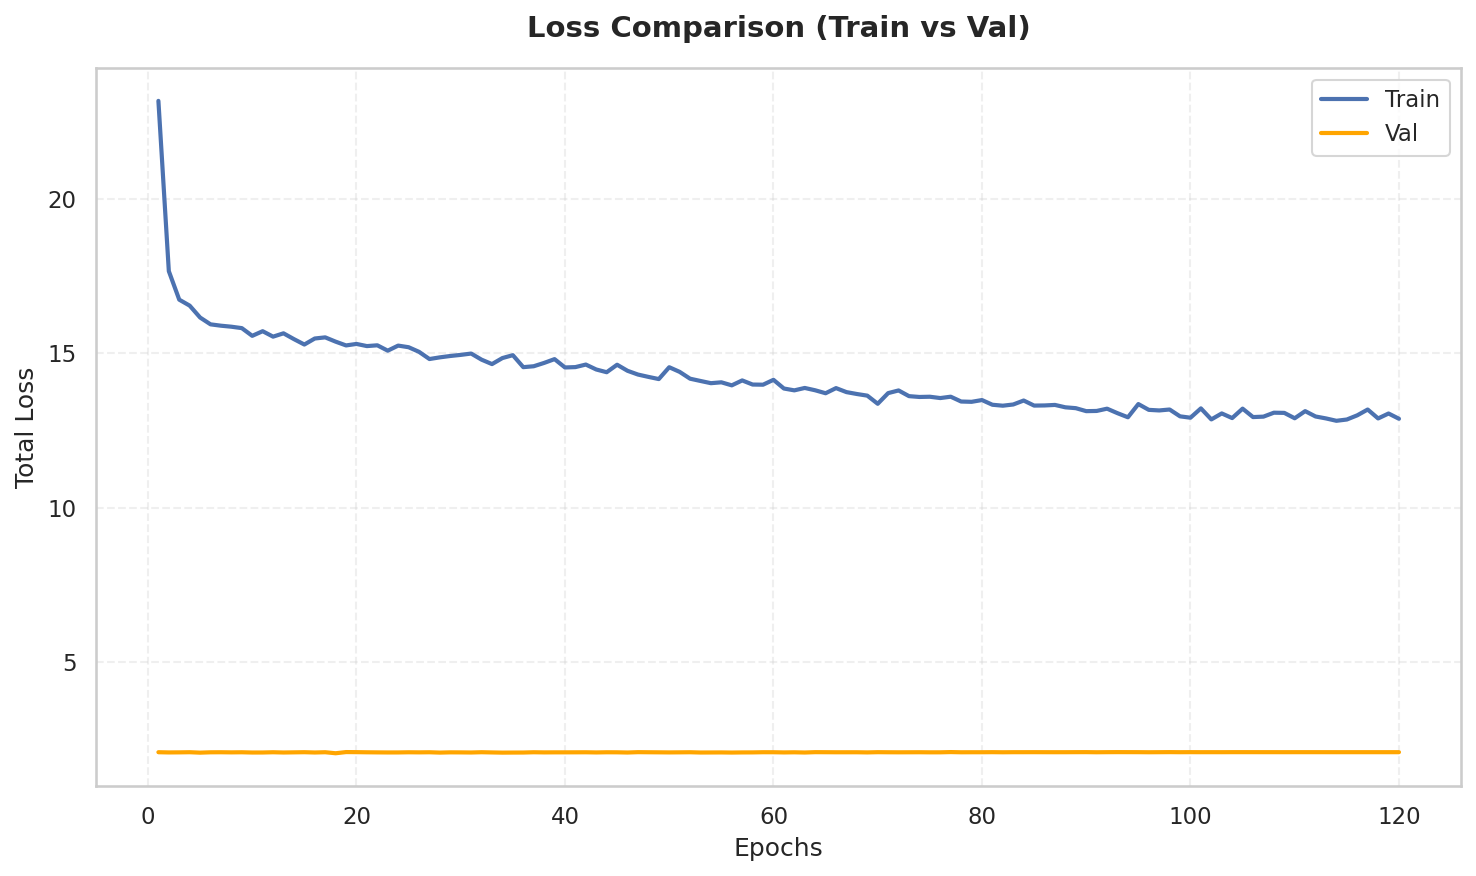

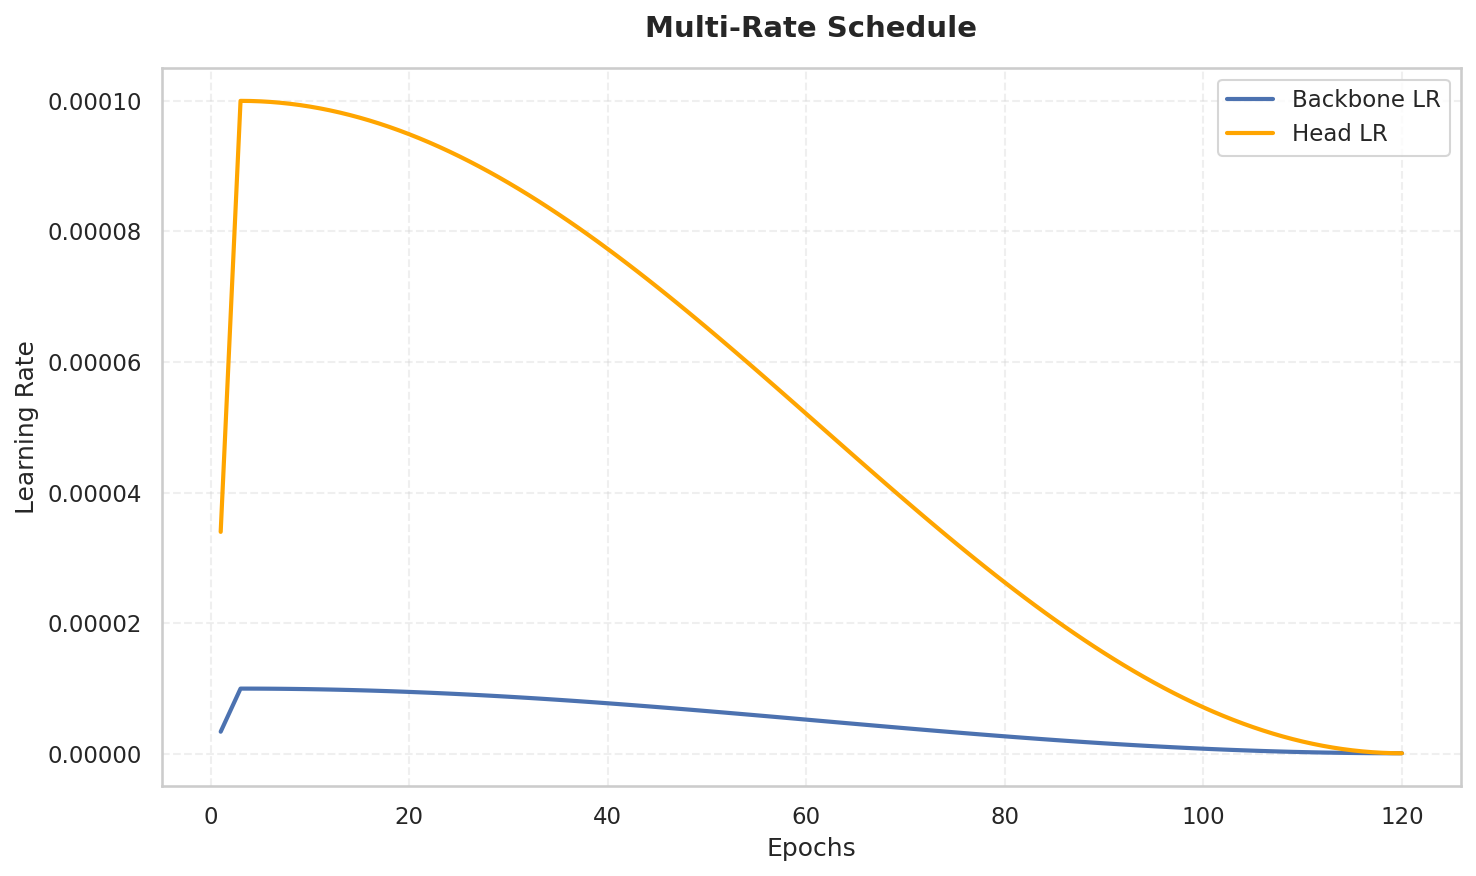

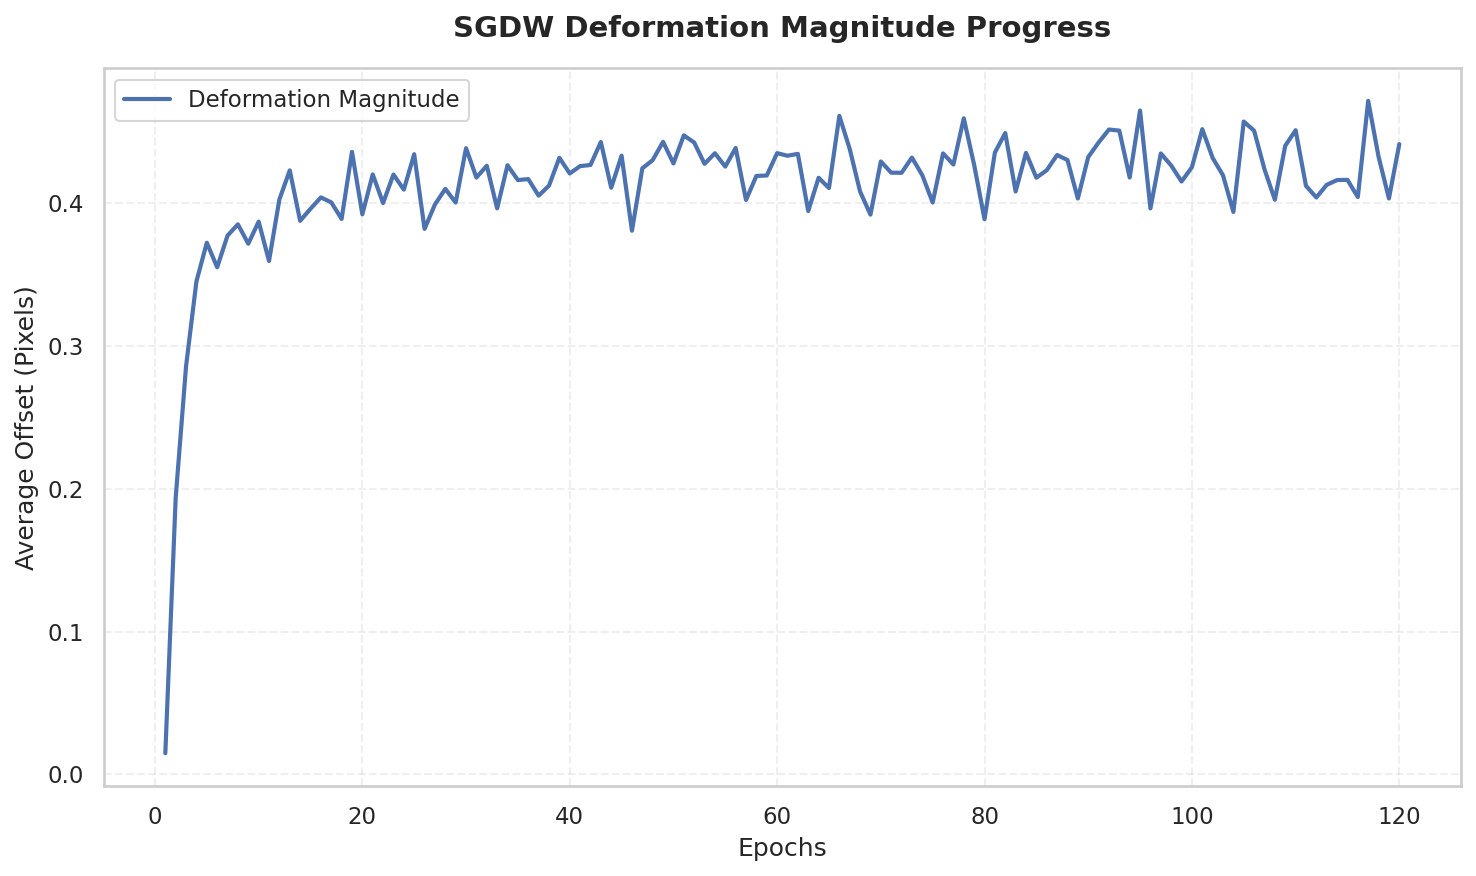

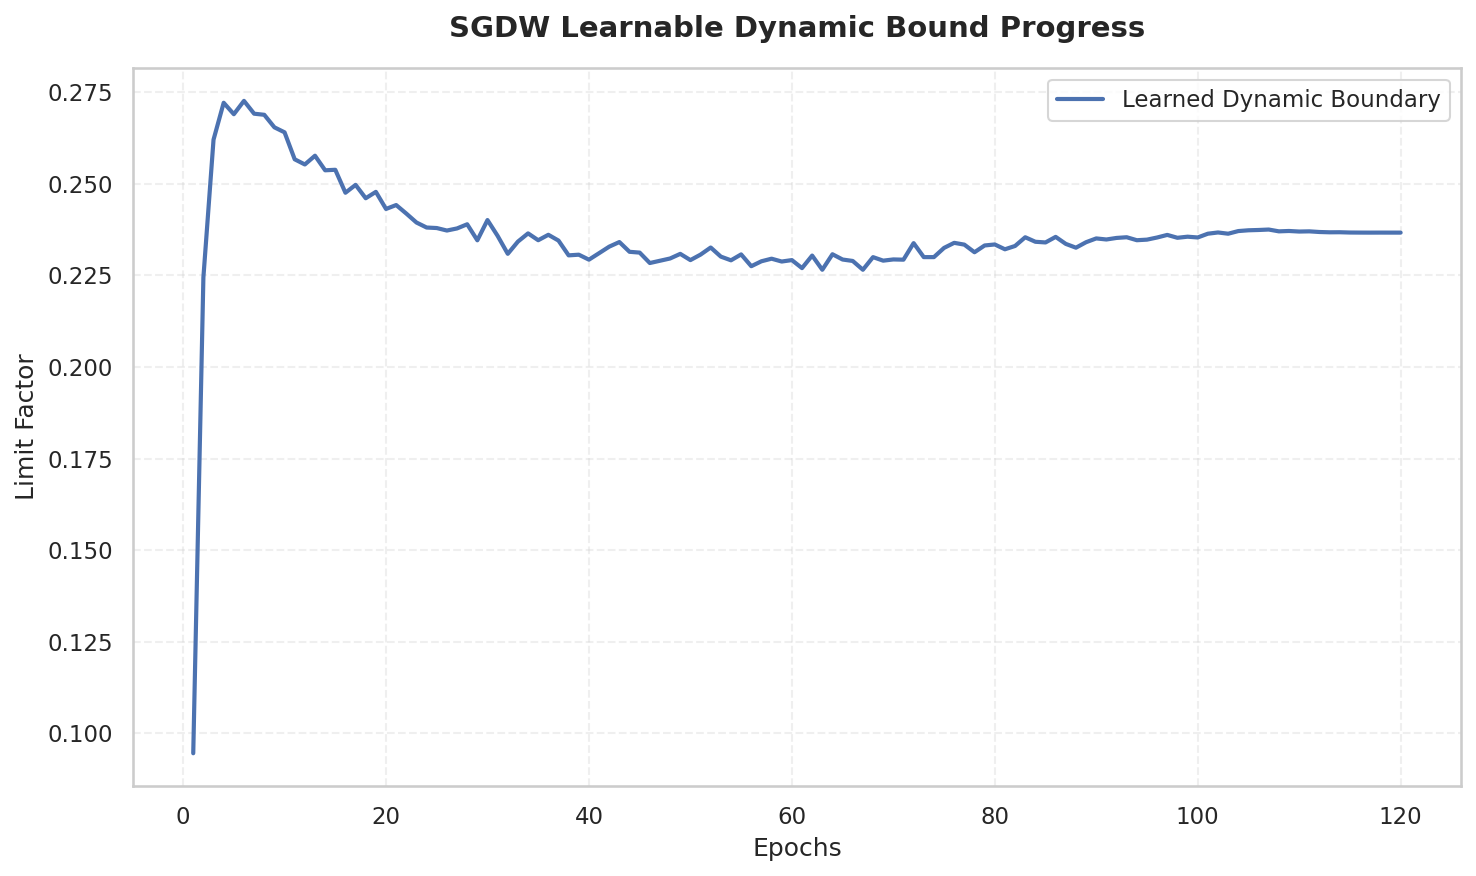

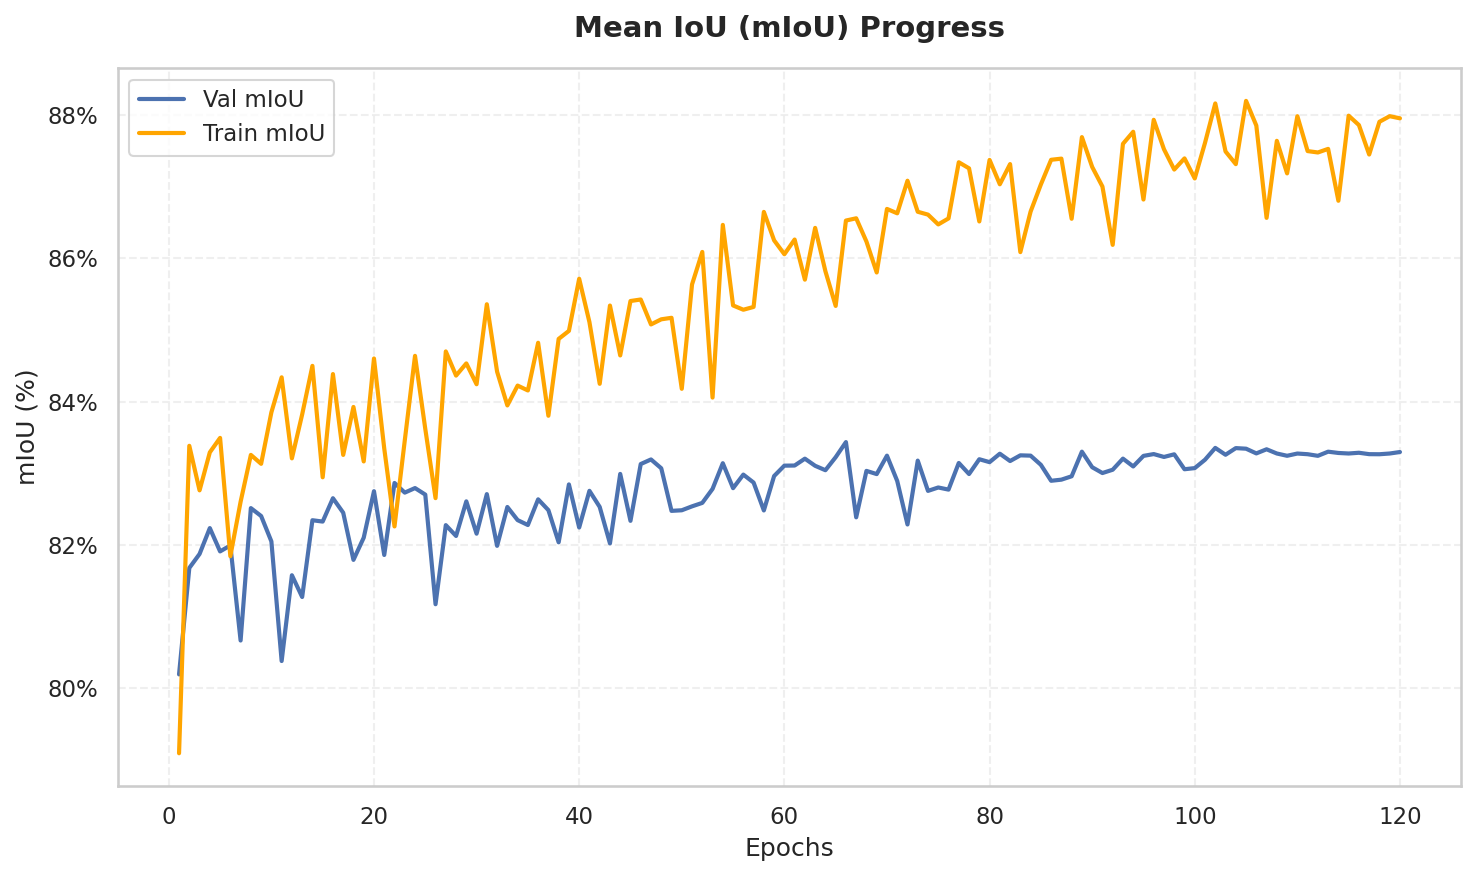

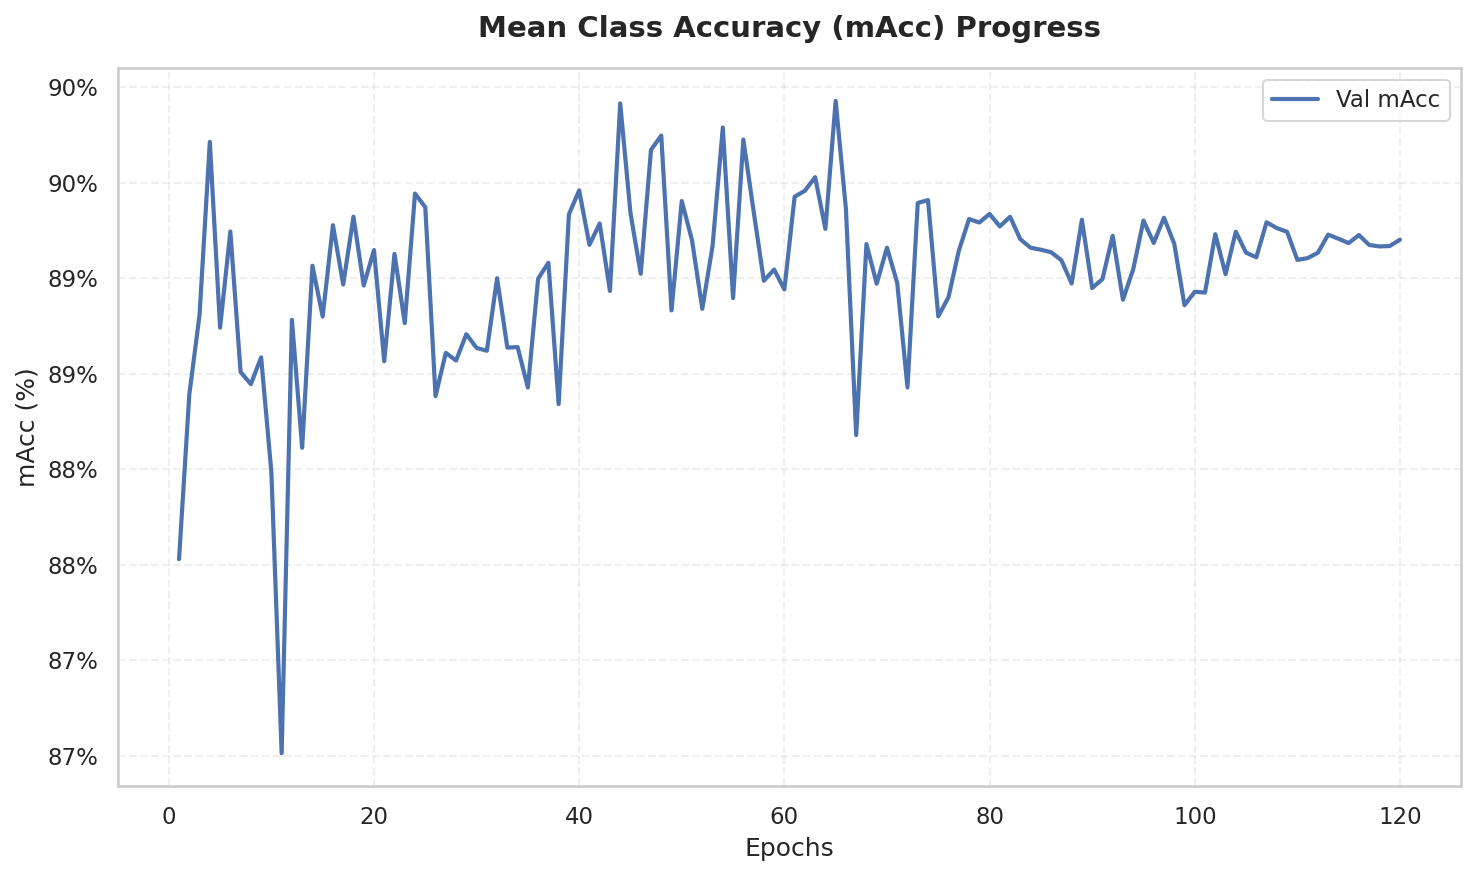

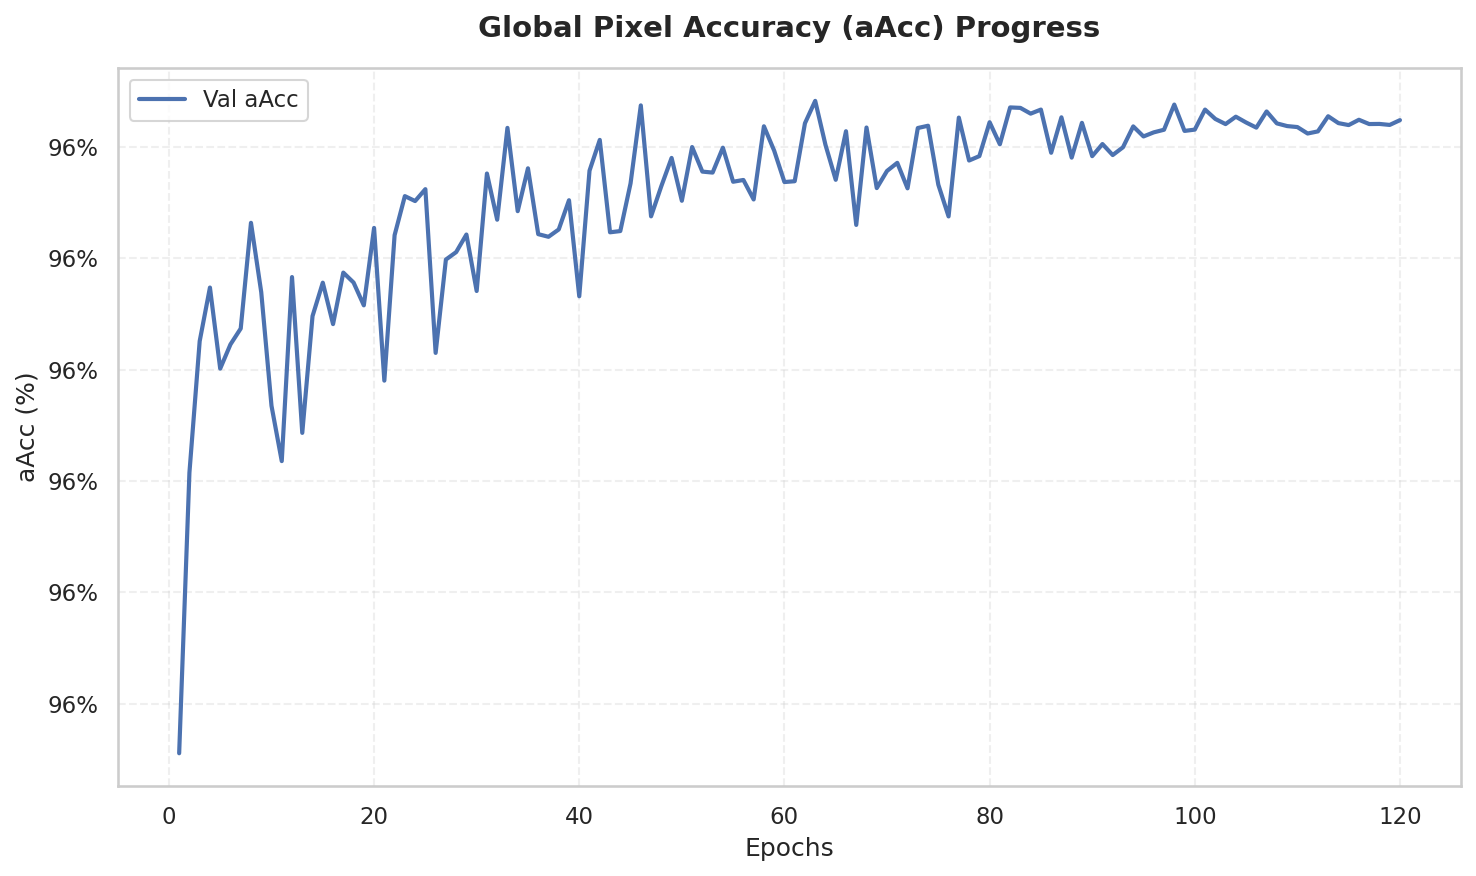

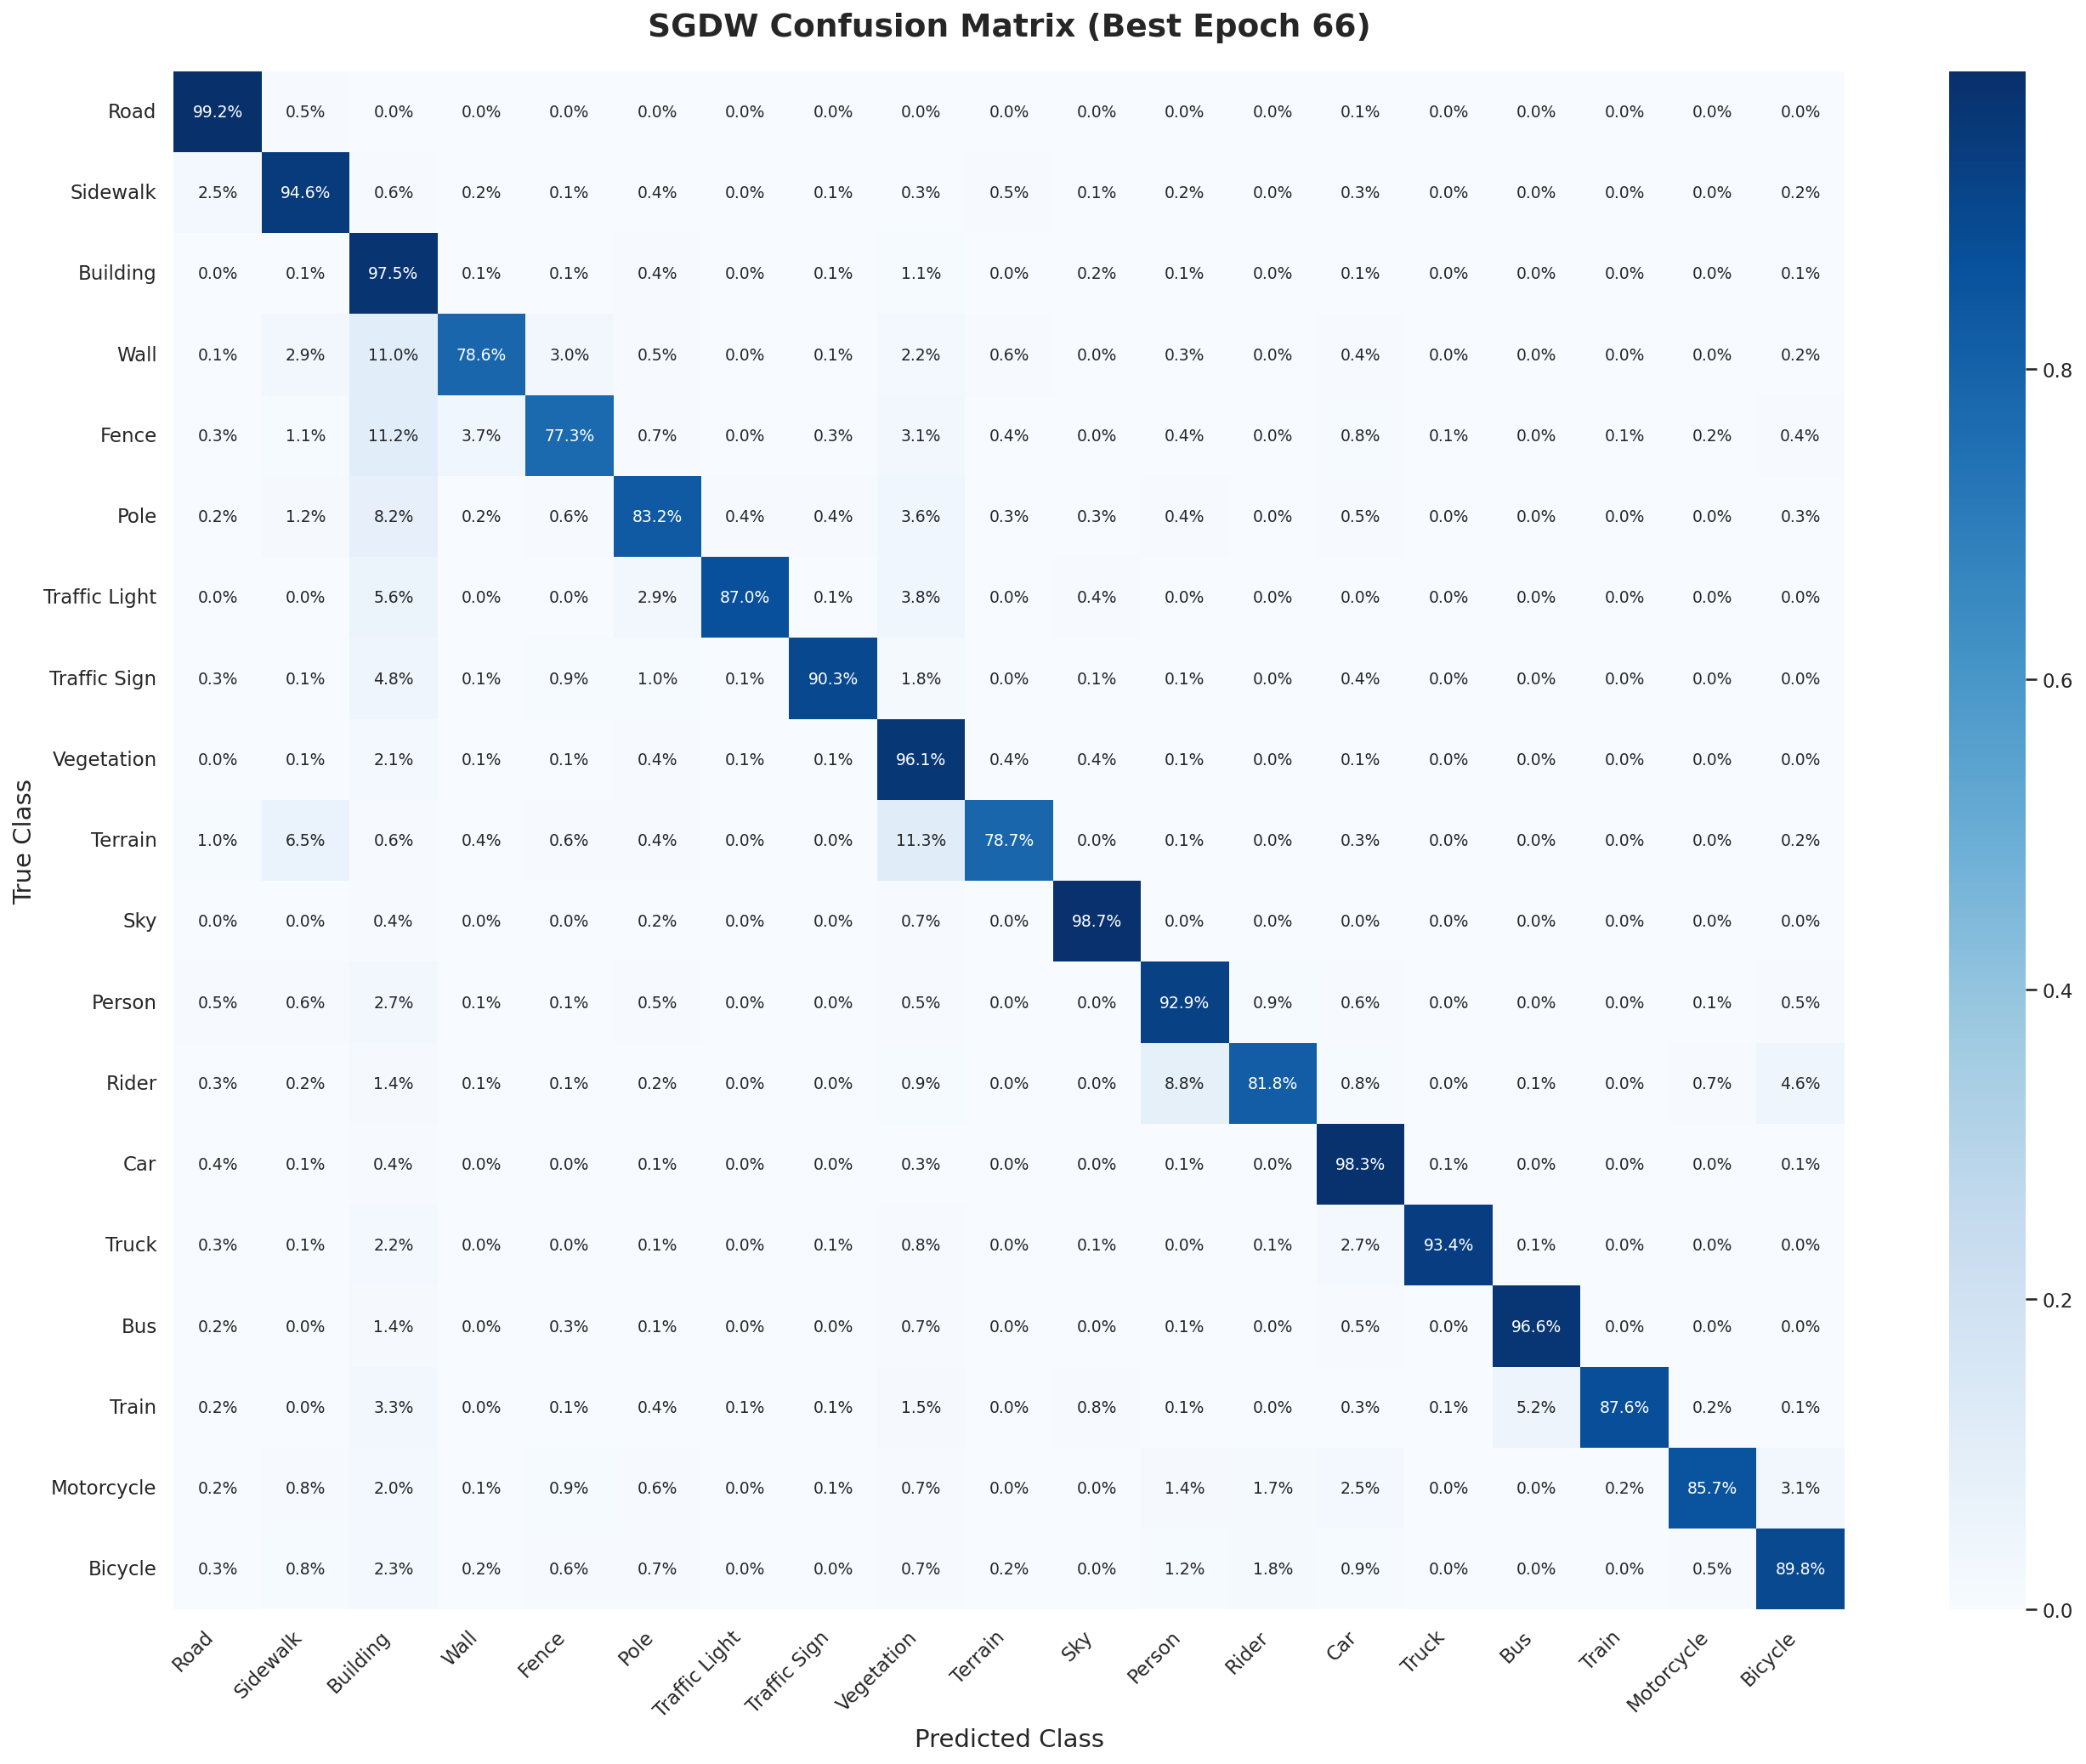


------------------------------------------------------------
Architecture: Multi-Scale SGDW with Dynamic Bounding
Decoder: Mask2Former (Bipartite Native)
Backbone: Swin-Small
Total Parameters:      70,377,100  (70.38 M)
Trainable Parameters:  70,376,524  (70.38 M)
------------------------------------------------------------
SUCCESS: All artifacts and graphs routed to:
/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS/Results_Export

FINAL RESULTS (Multi-Scale SGDW Architecture)
Best Validation mIoU:           83.43% (Epoch 66)
Final Epoch Pixel Acc (aAcc):   96.92%
Final Epoch Mean IoU (mIoU):    83.30%
Final Epoch Mean Class Acc:     89.70%
Total Training Time:            2 days, 18:00:03
------------------------------------------------------------
CLASS NAME           | IoU (%)    | Accuracy (%)
------------------------------------------------------------
Road                 | 98.68      | 99.19     
Sidewalk             | 88.68      | 94.61     
Building 

In [13]:
# ============================================================
# STEP 6: EXPORT RESULTS, PLOTS, CONFUSION MATRIX, FINAL SUMMARY
# Target Architecture: Multi-Scale SGDW Mask2Former (Swin-Small)
# Target Dataset: Cityscapes
# Optimized for: Automated Matrix Reconstruction, Class-Wise Parsing, 
# Percentage Matrices, Continuous Metric Plotting
# ============================================================

import os
import json
from pathlib import Path
from datetime import timedelta

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import torch.nn.functional as F

# ------------------------------------------------------------
# SAFETY CHECKS & PATH INHERITANCE
# ------------------------------------------------------------
required_globals = [
    "history", "model", "CLASS_NAMES", "CLASSES",
    "CHECKPOINT_DIR", "best_record", "DEVICE"
]
missing = [k for k in required_globals if k not in globals()]
if missing:
    raise NameError(f"Missing required variables from previous steps: {missing}")

IGNORE_INDEX = globals().get("IGNORE_INDEX", 255)
FINAL_SAVE_DIR = globals().get("FINAL_SAVE_DIR", Path("/home/hrusikesh-nishank/Pictures/SwinSmall_MultiScale_SGDW_Mask2Former_Cityscapes/Results_Export"))
FINAL_SAVE_DIR.mkdir(parents=True, exist_ok=True)
print(f"Final export directory validated: {FINAL_SAVE_DIR.resolve()}\n")

# ------------------------------------------------------------
# AUTOMATED MATRIX RECOVERY PROTOCOL (CRASH PROOF)
# ------------------------------------------------------------
BEST_CONF_MATRIX = globals().get("best_conf_matrix", globals().get("val_conf_matrix", None))

if BEST_CONF_MATRIX is None and "val_loader" in globals() and "model" in globals():
    print("[!] Confusion matrix missing from RAM. Reconstructing from Best Checkpoint...")
    best_ckpt_path = os.path.join(CHECKPOINT_DIR, "best_model_sgdw_cs.pt")
    
    if os.path.exists(best_ckpt_path):
        ckpt = torch.load(best_ckpt_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ckpt["model_state_dict"])
        model.eval()
        
        reconstructed_cm = np.zeros((CLASSES, CLASSES), dtype=np.int64)
        
        def _fast_confusion_matrix(y_true, y_pred, num_classes):
            idx = num_classes * y_true + y_pred
            return np.bincount(idx, minlength=num_classes**2).reshape(num_classes, num_classes)

        def _build_semantic_targets(mask_labels, class_labels, image_size):
            H, W = image_size
            targets = torch.full((len(mask_labels), H, W), fill_value=IGNORE_INDEX, dtype=torch.long, device=mask_labels[0].device)
            for b in range(len(mask_labels)):
                if class_labels[b].numel() == 0: continue
                for inst_idx, cls_id in enumerate(class_labels[b]):
                    if int(cls_id.item()) == IGNORE_INDEX: continue
                    targets[b][mask_labels[b][inst_idx] > 0.5] = int(cls_id.item())
            return targets
        
        USE_AMP = torch.cuda.is_available()
        pbar = tqdm(val_loader, total=len(val_loader), desc="Reconstructing Metrics (TTA)", leave=False)
        
        with torch.no_grad():
            for images, mask_labels, class_labels in pbar:
                images = images.to(DEVICE, non_blocking=True)
                _, _, val_h, val_w = images.shape
                
                mask_labels = [m.to(DEVICE, non_blocking=True) for m in mask_labels]
                class_labels = [c.to(DEVICE, non_blocking=True) for c in class_labels]
                dense_targets = _build_semantic_targets(mask_labels, class_labels, (val_h, val_w))

                scales = [0.75, 1.0, 1.25]
                final_logits = torch.zeros((images.shape[0], CLASSES, val_h, val_w), device=DEVICE, dtype=torch.float32)
                
                for scale in scales:
                    sH, sW = (int(val_h * scale) // 32) * 32, (int(val_w * scale) // 32) * 32 
                    scaled_img = F.interpolate(images, size=(sH, sW), mode='bilinear', align_corners=False)
                    
                    with torch.autocast(device_type="cuda", enabled=USE_AMP):
                        outputs = model(pixel_values=scaled_img)
                        m_preds = F.interpolate(outputs.masks_queries_logits, size=(val_h, val_w), mode="bilinear", align_corners=False)
                        m_cls = F.softmax(outputs.class_queries_logits, dim=-1)[..., :-1]
                        final_logits += torch.einsum("bqc,bqhw->bchw", m_cls, m_preds.sigmoid()).float()
                        
                        outputs_f = model(pixel_values=torch.flip(scaled_img, dims=[3]))
                        m_preds_f = F.interpolate(outputs_f.masks_queries_logits, size=(val_h, val_w), mode="bilinear", align_corners=False)
                        m_cls_f = F.softmax(outputs_f.class_queries_logits, dim=-1)[..., :-1]
                        flip_logits = torch.einsum("bqc,bqhw->bchw", m_cls_f, m_preds_f.sigmoid())
                        final_logits += torch.flip(flip_logits, dims=[3]).float()
                        
                semantic_logits = final_logits / (len(scales) * 2)
                
                preds = torch.argmax(semantic_logits, dim=1).cpu().numpy().astype(np.int64)
                targets_np = dense_targets.cpu().numpy().astype(np.int64)
                valid = (targets_np != IGNORE_INDEX)
                if valid.any():
                    reconstructed_cm += _fast_confusion_matrix(targets_np[valid], preds[valid], CLASSES)
                    
        BEST_CONF_MATRIX = reconstructed_cm
        print("[*] Reconstruction Complete! Restoring class-wise scores.")
    else:
        print("[!] Could not locate best checkpoint on disk. Class-wise metrics will remain empty.")

# ------------------------------------------------------------
# BUILD MAIN DATAFRAME
# ------------------------------------------------------------
num_epochs = len(history["epoch"])

def get_hist_col(key, fallback_key=None):
    col = history.get(key, [])
    if len(col) == num_epochs: return col
    if fallback_key and len(history.get(fallback_key, [])) == num_epochs: return history[fallback_key]
    if len(col) > 0:
        return col + [np.nan] * (num_epochs - len(col)) if len(col) < num_epochs else col[:num_epochs]
    return [np.nan] * num_epochs

df = pd.DataFrame({
    "Epoch": get_hist_col("epoch"),
    "Phase": get_hist_col("phase"),
    "Train_Total_Loss": get_hist_col("train_total_loss"),
    "Train_mIoU": get_hist_col("train_miou"),
    "Val_Total_Loss": get_hist_col("val_total_loss"),
    "Val_mIoU": get_hist_col("val_miou"),
    "Val_mAcc": get_hist_col("val_macc"),
    "Val_aAcc": get_hist_col("val_aacc"),
    "LR_Backbone": get_hist_col("backbone_lr"),
    "LR_Head": get_hist_col("head_lr"),
    "SGDW_Offset_Magnitude": get_hist_col("sgdw_offset_magnitude"),
    "SGDW_Dynamic_Bound": get_hist_col("sgdw_dynamic_bound"), 
    "Epoch_Time_sec": get_hist_col("epoch_time_sec"),
})

total_training_time_sec = float(df["Epoch_Time_sec"].sum()) if not df["Epoch_Time_sec"].isna().all() else 0.0
total_time_str = str(timedelta(seconds=int(total_training_time_sec)))
df["Total_Training_Session_Time"] = total_time_str

# ------------------------------------------------------------
# PREPARE CLASS-WISE DATA
# ------------------------------------------------------------
class_wise_data = []
if BEST_CONF_MATRIX is not None:
    tp = np.diag(BEST_CONF_MATRIX)
    fp = BEST_CONF_MATRIX.sum(axis=0) - tp
    fn = BEST_CONF_MATRIX.sum(axis=1) - tp
    
    iou_per_class = tp / (tp + fp + fn + 1e-10)
    acc_per_class = tp / (tp + fn + 1e-10)
    
    for i, name in enumerate(CLASS_NAMES):
        class_wise_data.append({
            "Class Name": name,
            "IoU (%)": float(iou_per_class[i] * 100),
            "Accuracy (%)": float(acc_per_class[i] * 100)
        })

# ------------------------------------------------------------
# EXPORT FINAL RESULTS CSV & EXCEL
# ------------------------------------------------------------
def safe_pct(val):
    if pd.isna(val) or np.isnan(val): return 0.0
    return val if val > 1.0 else val * 100.0

final_v_acc = safe_pct(df["Val_aAcc"].iloc[-1])
final_mIoU = safe_pct(df["Val_mIoU"].iloc[-1])
final_mAcc = safe_pct(df["Val_mAcc"].iloc[-1])

if "val_miou" in history and len(history["val_miou"]) > 0:
    best_miou_raw = max(history["val_miou"])
    best_idx = history["val_miou"].index(best_miou_raw)
    best_epoch = history["epoch"][best_idx]
    best_miou = safe_pct(best_miou_raw)
else:
    best_epoch = best_record.get("best_epoch", -1)
    best_miou = safe_pct(best_record.get("best_miou", 0.0))

final_global_data = [
    {"Metric": "Best Validation mIoU", "Value": f"{best_miou:.2f}%"},
    {"Metric": "Global Pixel Accuracy (aAcc)", "Value": f"{final_v_acc:.2f}%"},
    {"Metric": "Final Epoch Mean IoU (mIoU)", "Value": f"{final_mIoU:.2f}%"},
    {"Metric": "Final Epoch Mean Class Accuracy (mAcc)", "Value": f"{final_mAcc:.2f}%"},
    {"Metric": "Total Training Time", "Value": total_time_str}
]
pd.DataFrame(final_global_data).to_csv(FINAL_SAVE_DIR / "finalresults_sgdw.csv", index=False)

excel_path = FINAL_SAVE_DIR / "Training_Metrics_Report_SGDW.xlsx"
with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    df.to_excel(writer, sheet_name='Epoch_Metrics', index=False)
    if class_wise_data:
        pd.DataFrame(class_wise_data).to_excel(writer, sheet_name='Class_Wise_Results', index=False)

# ------------------------------------------------------------
# STANDARD SEPARATE PLOTS (INDIVIDUAL METRICS)
# ------------------------------------------------------------
sns.set_style("whitegrid")

def save_separate_plot(filename, title, ylabel, train_data, val_data=None, label1="Train", label2="Val"):
    plt.figure(figsize=(10, 6))
    
    epochs_range = range(1, len(train_data) + 1)
    train_clean = np.array(train_data, dtype=float)
    
    if not np.isnan(train_clean).all():
        plt.plot(epochs_range, train_clean, label=label1, lw=2)
    
    if val_data is not None:
        val_clean = np.array(val_data, dtype=float)
        if not np.isnan(val_clean).all():
            plt.plot(epochs_range, val_clean, label=label2, lw=2, color='orange')
            
    if "(%)" in ylabel:
        plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}%".format(int(x))))

    plt.title(title, fontsize=14, fontweight='bold', pad=15)
    plt.xlabel("Epochs", fontsize=12)
    plt.ylabel(ylabel, fontsize=12)
    plt.legend()
    plt.grid(True, alpha=0.3, linestyle='--')
    plt.tight_layout()
    plt.savefig(FINAL_SAVE_DIR / f"{filename}.png", dpi=600, bbox_inches='tight')
    plt.show() 
    plt.close()

# Extract Data
train_loss = df["Train_Total_Loss"].tolist()
val_loss = df["Val_Total_Loss"].tolist()
offset_magnitude = df["SGDW_Offset_Magnitude"].tolist()
dynamic_bound = df["SGDW_Dynamic_Bound"].tolist()

def ensure_percentage(series):
    if series.isna().all(): return None
    data = series.tolist()
    return [x * 100 if (x is not None and x <= 1.0) else x for x in data]

train_miou = ensure_percentage(df["Train_mIoU"])
val_miou = ensure_percentage(df["Val_mIoU"])
val_aacc = ensure_percentage(df["Val_aAcc"])
val_macc = ensure_percentage(df["Val_mAcc"])

lr_backbone = df["LR_Backbone"].tolist()
lr_head = df["LR_Head"].tolist()

# 1. Loss & Mechanics Plots
save_separate_plot("loss_comparison", "Loss Comparison (Train vs Val)", "Total Loss", train_loss, val_loss)
save_separate_plot("learning_rate_progress", "Multi-Rate Schedule", "Learning Rate", lr_backbone, lr_head, label1="Backbone LR", label2="Head LR")
if not df["SGDW_Offset_Magnitude"].isna().all():
    save_separate_plot("sgdw_offset_magnitude", "SGDW Deformation Magnitude Progress", "Average Offset (Pixels)", offset_magnitude, label1="Deformation Magnitude")
if not df["SGDW_Dynamic_Bound"].isna().all():
    save_separate_plot("sgdw_dynamic_bound", "SGDW Learnable Dynamic Bound Progress", "Limit Factor", dynamic_bound, label1="Learned Dynamic Boundary")

# 2. Individual Evaluation Metric Plots
save_separate_plot("miou_progress", "Mean IoU (mIoU) Progress", "mIoU (%)", val_miou, train_miou, label1="Val mIoU", label2="Train mIoU")
save_separate_plot("macc_progress", "Mean Class Accuracy (mAcc) Progress", "mAcc (%)", val_macc, label1="Val mAcc")
save_separate_plot("aacc_progress", "Global Pixel Accuracy (aAcc) Progress", "aAcc (%)", val_aacc, label1="Val aAcc")

# ------------------------------------------------------------
# PERCENTAGE-BASED CONFUSION MATRIX
# ------------------------------------------------------------
if BEST_CONF_MATRIX is not None:
    plt.figure(figsize=(18, 14)) 
    
    cm_normalized = BEST_CONF_MATRIX.astype('float') / (BEST_CONF_MATRIX.sum(axis=1)[:, np.newaxis] + 1e-10)
    
    sns.heatmap(
        cm_normalized, annot=True, fmt='.1%', cmap='Blues', 
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, 
        annot_kws={"size": 9}
    ) 
    
    plt.title(f"SGDW Confusion Matrix (Best Epoch {best_epoch})", fontsize=18, fontweight='bold', pad=20)
    plt.ylabel('True Class', fontsize=14)
    plt.xlabel('Predicted Class', fontsize=14)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig(FINAL_SAVE_DIR / "confusion_matrix_percentages.png", dpi=600, bbox_inches='tight')
    plt.show() 
    plt.close()

# ------------------------------------------------------------
# FINAL PRINT SUMMARY
# ------------------------------------------------------------
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"\n" + "-"*60)
print(f"Architecture: Multi-Scale SGDW with Dynamic Bounding")
print(f"Decoder: Mask2Former (Bipartite Native)")
print(f"Backbone: Swin-Small")
print(f"Total Parameters:      {total_params:,}  ({total_params/1e6:.2f} M)")
print(f"Trainable Parameters:  {trainable_params:,}  ({trainable_params/1e6:.2f} M)")
print(f"-"*60)
print(f"SUCCESS: All artifacts and graphs routed to:\n{FINAL_SAVE_DIR.resolve()}")
print("\n" + "="*60)
print(f"FINAL RESULTS (Multi-Scale SGDW Architecture)")
print("="*60)
print(f"Best Validation mIoU:           {best_miou:.2f}% (Epoch {best_epoch})")
print(f"Final Epoch Pixel Acc (aAcc):   {final_v_acc:.2f}%")
print(f"Final Epoch Mean IoU (mIoU):    {final_mIoU:.2f}%")
print(f"Final Epoch Mean Class Acc:     {final_mAcc:.2f}%")
print(f"Total Training Time:            {total_time_str}")
print("-" * 60)
print(f"{'CLASS NAME':<20} | {'IoU (%)':<10} | {'Accuracy (%)':<10}")
print("-" * 60)

if class_wise_data:
    for item in class_wise_data:
        print(f"{item['Class Name']:<20} | {item['IoU (%)']:<10.2f} | {item['Accuracy (%)']:<10.2f}")

Presentation graph will be exported to: /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS/Results_Export
[*] Filtered presentation graph saved successfully to:
/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS/Results_Export/presentation_metrics_progress_sgdw.png


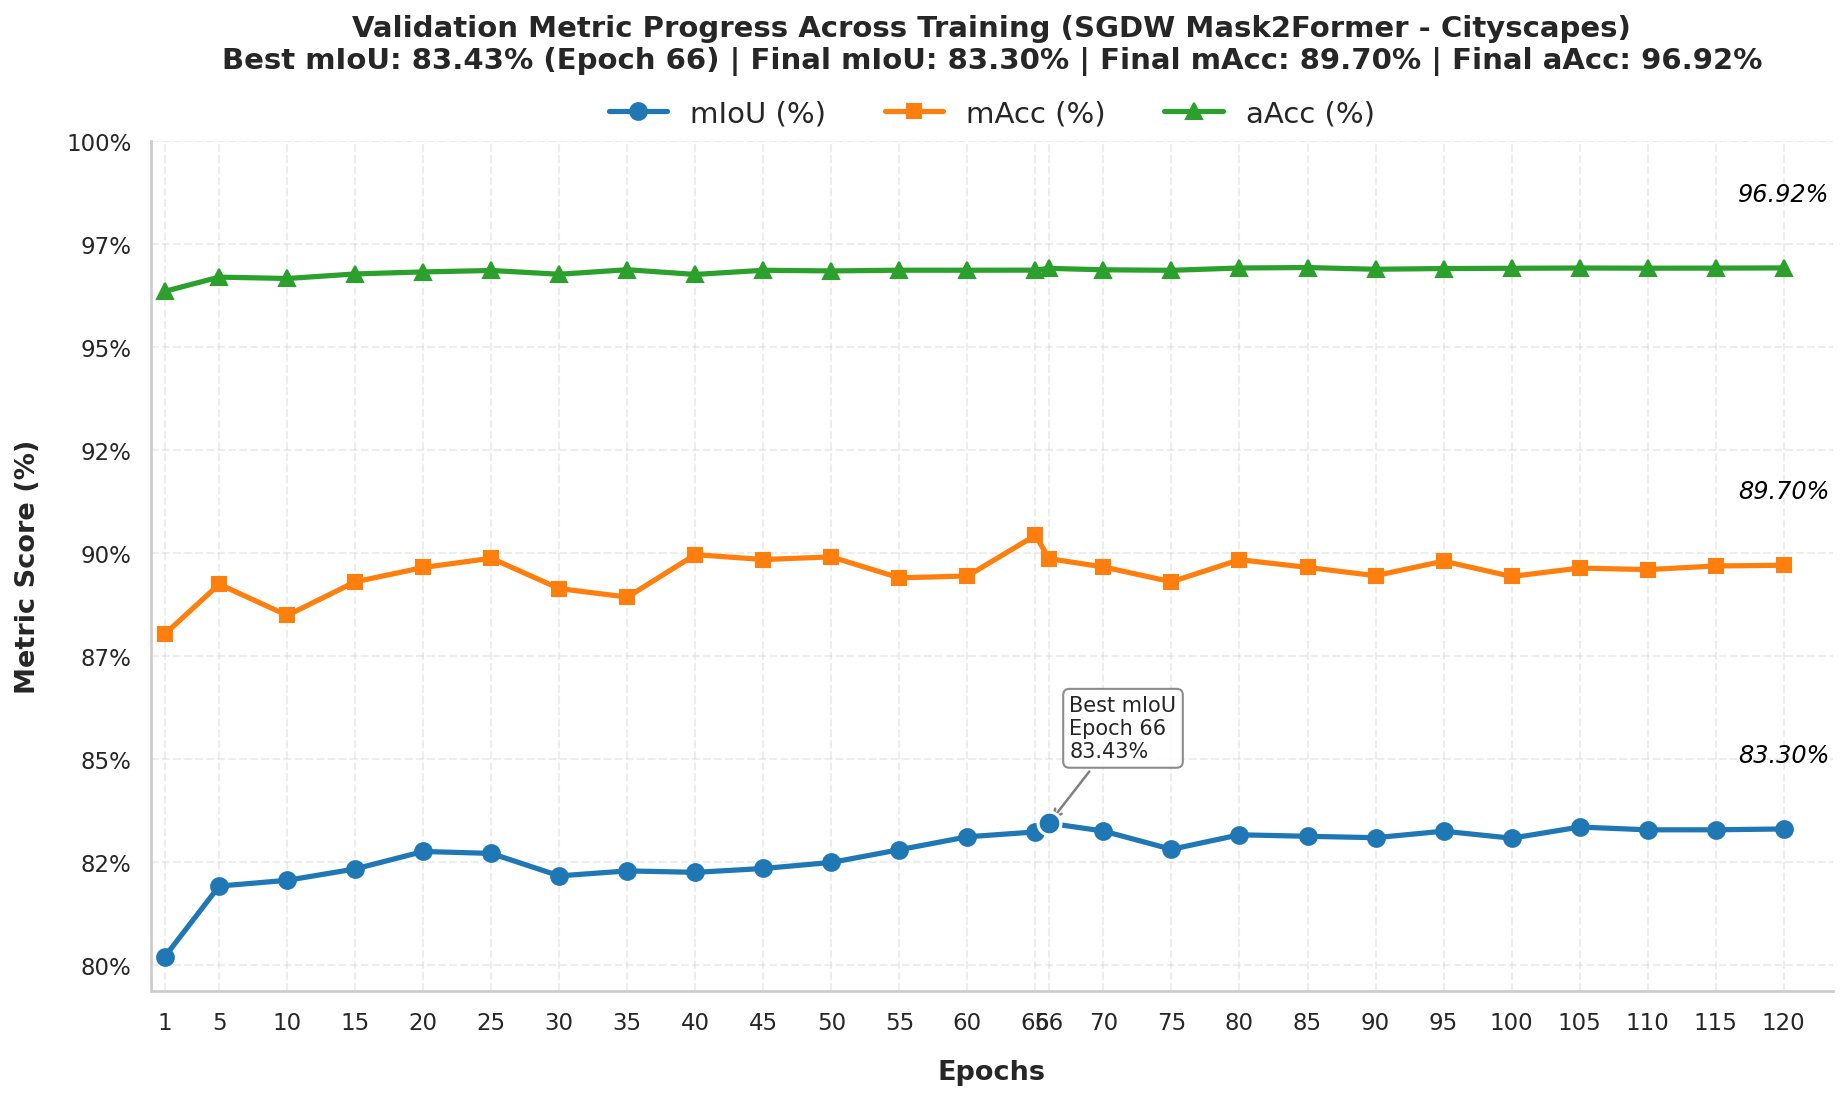

In [14]:
# ============================================================
# STEP 7: PRESENTATION-READY MULTI-METRIC PROGRESS GRAPH
# Target Architecture: Semantically-Guided Deformable Windows (SGDW) Swin-Small
# Target Dataset: Cityscapes
# Optimized for: Global Path Inheritance, Specific Epoch Intervals,
# and Strict Percentage Scaling for Publication
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# SAFETY CHECKS & PATH INHERITANCE
# ------------------------------------------------------------
required_globals = ["history"]
missing = [k for k in required_globals if k not in globals()]
if missing:
    raise NameError(f"Missing required variables from previous steps: {missing}")

if "val_miou" not in history or len(history["val_miou"]) == 0:
    raise ValueError("history['val_miou'] is empty. Run training (Step 5) before Step 7.")

# Inherit the centralized export directory securely from Step 1
FINAL_SAVE_DIR = globals().get("FINAL_SAVE_DIR", Path("/home/hrusikesh-nishank/Pictures/swinsmall_SGDW_Mask2Former_CS/Results_Export"))
FINAL_SAVE_DIR.mkdir(parents=True, exist_ok=True)
print(f"Presentation graph will be exported to: {FINAL_SAVE_DIR.resolve()}")

# ------------------------------------------------------------
# PREPARE EPOCHS & DATA
# ------------------------------------------------------------
all_epochs = history["epoch"]
PLOT_INTERVAL = 5

# Safe percentage converter (prevents 80% turning into 8000% if already scaled in Step 5)
def safe_pct(val):
    if pd.isna(val) or np.isnan(val): return 0.0
    return val * 100.0 if val <= 1.0 else float(val)

# Bulletproof Best Epoch Extraction
best_miou_raw = max(history["val_miou"])
best_idx = history["val_miou"].index(best_miou_raw)
best_miou = safe_pct(best_miou_raw)
best_miou_epoch = all_epochs[best_idx]

# Filter epochs to reduce visual clutter: Epoch 1, every nth epoch, best epoch, final epoch
filtered_epochs_set = set([e for e in all_epochs if e == 1 or e % PLOT_INTERVAL == 0] + [all_epochs[-1], best_miou_epoch])
filtered_epochs = sorted(list(filtered_epochs_set))

indices = [all_epochs.index(e) for e in filtered_epochs]

# Extract and convert to percentages for cleaner presentation
miou_scores = [safe_pct(history["val_miou"][i]) for i in indices]
macc_scores = [safe_pct(history["val_macc"][i]) for i in indices]
aacc_scores = [safe_pct(history["val_aacc"][i]) for i in indices]

final_miou = safe_pct(history["val_miou"][-1])
final_macc = safe_pct(history["val_macc"][-1])
final_aacc = safe_pct(history["val_aacc"][-1])
final_x = all_epochs[-1]

# ------------------------------------------------------------
# PLOT SETUP 
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12.5, 7.5)) 

color_miou = '#1f77b4'  # Blue
color_macc = '#ff7f0e'  # Orange
color_aacc = '#2ca02c'  # Green

ax.plot(filtered_epochs, miou_scores, marker='o', linewidth=2.5, markersize=8, label='mIoU (%)', color=color_miou)
ax.plot(filtered_epochs, macc_scores, marker='s', linewidth=2.5, markersize=7, label='mAcc (%)', color=color_macc)
ax.plot(filtered_epochs, aacc_scores, marker='^', linewidth=2.5, markersize=8, label='aAcc (%)', color=color_aacc)

# ------------------------------------------------------------
# AXIS LABELS
# ------------------------------------------------------------
ax.set_xlabel('Epochs', fontsize=13, fontweight='bold', labelpad=12)
ax.set_ylabel('Metric Score (%)', fontsize=13, fontweight='bold', labelpad=12)
ax.set_xticks(filtered_epochs)

# Force the Y-axis to display percent signs natively
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{int(x)}%"))

# ------------------------------------------------------------
# BEST mIoU ANNOTATION 
# ------------------------------------------------------------
ax.scatter(best_miou_epoch, best_miou, s=120, zorder=5, color=color_miou, edgecolors='white', linewidth=1.5)

if best_miou_epoch <= (max(filtered_epochs) * 0.6):
    best_text_x = best_miou_epoch + 1.5
    best_ha = "left"
else:
    best_text_x = best_miou_epoch - 1.5
    best_ha = "right"

ax.annotate(
    f'Best mIoU\nEpoch {best_miou_epoch}\n{best_miou:.2f}%',
    xy=(best_miou_epoch, best_miou),
    xytext=(best_text_x, best_miou + 1.5),
    fontsize=10, ha=best_ha, va='bottom',
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.9),
    arrowprops=dict(arrowstyle='->', color='gray', lw=1.2)
)

# ------------------------------------------------------------
# END-OF-LINE FINAL VALUE ANNOTATIONS (Floating above markers)
# ------------------------------------------------------------
# Placed slightly above the final points to match the target aesthetic
offset_y = 1.5

ax.text(final_x, final_miou + offset_y, f'{final_miou:.2f}%', va='bottom', ha='center', fontsize=11.5, fontstyle='italic', color='black')
ax.text(final_x, final_macc + offset_y, f'{final_macc:.2f}%', va='bottom', ha='center', fontsize=11.5, fontstyle='italic', color='black')
ax.text(final_x, final_aacc + offset_y, f'{final_aacc:.2f}%', va='bottom', ha='center', fontsize=11.5, fontstyle='italic', color='black')

ax.set_xlim(left=0, right=max(all_epochs) + (max(all_epochs) * 0.03))
ax.set_ylim(top=100) 

# ------------------------------------------------------------
# STYLING & LEGEND
# ------------------------------------------------------------
# Center the legend horizontally above the plot area
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.08), ncol=3, frameon=False, fontsize=14)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(1.3)
ax.spines['left'].set_linewidth(1.3)

ax.grid(True, linestyle='--', alpha=0.35)

title_main = "Validation Metric Progress Across Training (SGDW Mask2Former - Cityscapes)"
title_sub = f"Best mIoU: {best_miou:.2f}% (Epoch {best_miou_epoch}) | Final mIoU: {final_miou:.2f}% | Final mAcc: {final_macc:.2f}% | Final aAcc: {final_aacc:.2f}%"

# Pushed the title up slightly to make room for the new legend position
ax.set_title(
    title_main + "\n" + title_sub,
    fontsize=14, fontweight='bold', pad=35
)

plt.tight_layout()

# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------
# Directly save the single, unified presentation-ready graph
combined_graph_path = FINAL_SAVE_DIR / "presentation_metrics_progress_sgdw.png"
plt.savefig(combined_graph_path, dpi=600, bbox_inches='tight')
print(f"[*] Filtered presentation graph saved successfully to:\n{combined_graph_path.resolve()}")

plt.show()
plt.close()

In [15]:
# ============================================================
# CITYSCAPES TEST SET EVALUATION & SUBMISSION EXPORT
# Target Architecture: SGDW-Enhanced Swin-Small (Pixel Decoder)
# Target Dataset: Cityscapes (Test Split)
# Note: No GT exists in 'test'. Calculates visuals and submission masks.
# ============================================================

import os
import cv2
import time
import torch
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm import tqdm
import torch.nn.functional as F

# Clear cache before running
torch.cuda.empty_cache()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CLASSES = 19

# ------------------------------------------------------------
# HIGH CONTRAST PALETTE & SUBMISSION MAPPING
# ------------------------------------------------------------
HIGH_CONTRAST_PALETTE = np.array([
    [255, 255, 255],   # 0: Road
    [240, 30, 200],    # 1: Sidewalk
    [60, 80, 120],     # 2: Building
    [130, 90, 60],     # 3: Wall
    [180, 130, 50],    # 4: Fence
    [200, 200, 200],   # 5: Pole
    [255, 50, 50],     # 6: Traffic Light
    [50, 255, 255],    # 7: Traffic Sign
    [0, 180, 80],      # 8: Vegetation
    [120, 160, 40],    # 9: Terrain
    [0, 0, 0],         # 10: Sky
    [255, 255, 0],     # 11: Person
    [255, 160, 0],     # 12: Rider
    [0, 0, 255],       # 13: Car
    [0, 0, 130],       # 14: Truck
    [0, 120, 255],     # 15: Bus
    [100, 0, 100],     # 16: Train
    [0, 150, 150],     # 17: Motorcycle
    [180, 0, 0]        # 18: Bicycle
], dtype=np.uint8)

# Official mapping to convert 19 TrainIDs back to 34 Cityscapes Eval IDs
trainId_to_cityscapesId = {
    0: 7, 1: 8, 2: 11, 3: 12, 4: 13, 5: 17, 6: 19, 7: 20, 8: 21, 
    9: 22, 10: 23, 11: 24, 12: 25, 13: 26, 14: 27, 15: 28, 
    16: 31, 17: 32, 18: 33
}

def decode_segmap_high_contrast(segmentation_map):
    h, w = segmentation_map.shape
    rgb = np.zeros((h, w, 3), dtype=np.uint8)
    valid_mask = (segmentation_map >= 0) & (segmentation_map < CLASSES)
    for label, color in enumerate(HIGH_CONTRAST_PALETTE):
        rgb[segmentation_map == label] = color
    rgb[~valid_mask] = np.array([0, 0, 0], dtype=np.uint8)
    return rgb

# ------------------------------------------------------------
# 1. DIRECTORY CONFIGURATION
# ------------------------------------------------------------
# Cityscapes Test Directory
TEST_IMG_DIR = Path("/home/hrusikesh-nishank/miniconda3/envs/Segmentation/Datasets/leftImg8bit_trainvaltest/leftImg8bit/test")

# Result Export Paths
BASE_SAVE_DIR = Path("/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS")
EXPORT_DIR = BASE_SAVE_DIR / "Cityscapes_Test_Results"
VISUAL_DIR = EXPORT_DIR / "Visual_Predictions_HighContrast"
SUBMISSION_DIR = EXPORT_DIR / "Submission_Masks" # Official format masks go here

# Model Checkpoint Path
CHECKPOINT_PATH = BASE_SAVE_DIR / "Results_Export/progressive_checkpoints_sgdw_v2_cs/best_model_sgdw_cs.pt"

EXPORT_DIR.mkdir(parents=True, exist_ok=True)
VISUAL_DIR.mkdir(parents=True, exist_ok=True)
SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. LOAD MODEL
# ------------------------------------------------------------
if 'model' not in globals():
    raise NameError("Model not found in memory! Ensure Step 4 is run before executing this cell.")

if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(f"SGDW Checkpoint not found at: {CHECKPOINT_PATH.resolve()}")

print("Loading Best SGDW Mask2Former Checkpoint...")
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

# ------------------------------------------------------------
# 3. FILE DISCOVERY
# ------------------------------------------------------------
image_files = sorted(list(TEST_IMG_DIR.rglob("*_leftImg8bit.png")))

if len(image_files) == 0:
    print(f"\n[!] ERROR: No images found in {TEST_IMG_DIR}")
else:
    print(f"Found {len(image_files)} test images. Initiating inference...\n")
    
    total_inference_time = 0.0
    
    # ------------------------------------------------------------
    # 4. INFERENCE & EXPORT LOOP
    # ------------------------------------------------------------
    with torch.no_grad():
        for img_path in tqdm(image_files, desc="Processing Test Split"):
            img_bgr = cv2.imread(str(img_path))
            if img_bgr is None: continue
            
            # Prepare image for network
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            img_norm = img_rgb / 255.0
            img_norm = (img_norm - np.array([0.485, 0.456, 0.406])) / np.array([0.229, 0.224, 0.225])
            img_tensor = torch.tensor(img_norm).permute(2, 0, 1).unsqueeze(0).float().to(DEVICE)
            
            if torch.cuda.is_available(): torch.cuda.synchronize()
            start_time = time.time()
            
            # Inference
            with torch.autocast(device_type="cuda", enabled=torch.cuda.is_available()):
                outputs = model(pixel_values=img_tensor)
                H, W = img_tensor.shape[2], img_tensor.shape[3]
                
                mask_preds_up = F.interpolate(outputs.masks_queries_logits, size=(H, W), mode="bilinear", align_corners=False)
                mask_cls = F.softmax(outputs.class_queries_logits, dim=-1)[..., :-1]
                semantic_logits = torch.einsum("bqc,bqhw->bchw", mask_cls, mask_preds_up.sigmoid())
                pred_mask = torch.argmax(semantic_logits, dim=1).squeeze(0)
                
            if torch.cuda.is_available(): torch.cuda.synchronize()
            end_time = time.time()
            total_inference_time += (end_time - start_time)
            
            pred_mask_np = pred_mask.cpu().numpy().astype(np.uint8)

            # --- A. SAVE SUBMISSION MASK ---
            # Remap 19 TrainIDs to 34 Cityscapes IDs for benchmark submission
            submission_mask = np.zeros_like(pred_mask_np, dtype=np.uint8)
            for train_id, cityscapes_id in trainId_to_cityscapesId.items():
                submission_mask[pred_mask_np == train_id] = cityscapes_id
            
            # Cityscapes requires format: city_frame_pred.png
            mask_filename = img_path.name.replace("_leftImg8bit.png", "_pred.png")
            cv2.imwrite(str(SUBMISSION_DIR / mask_filename), submission_mask)

            # --- B. SAVE VISUALIZATION ---
            # Create a 2-panel side-by-side plot (Original vs Predicted)
            fig, axes = plt.subplots(2, 1, figsize=(12, 8))
            
            axes[0].imshow(img_rgb)
            axes[0].set_title(f"Cityscapes Test Image: {img_path.name}")
            axes[0].axis('off')
            
            axes[1].imshow(decode_segmap_high_contrast(pred_mask_np))
            axes[1].set_title("SGDW Model Prediction (High Contrast)")
            axes[1].axis('off')
            
            plt.tight_layout()
            plt.savefig(VISUAL_DIR / f"{img_path.stem}_visual.png", dpi=300, bbox_inches="tight")
            plt.close(fig)

    # ------------------------------------------------------------
    # 5. FINAL SUMMARY
    # ------------------------------------------------------------
    avg_time_per_frame = (total_inference_time / len(image_files)) * 1000
    fps = 1.0 / (total_inference_time / len(image_files))
    
    print("\n=================================================================")
    print(" CITYSCAPES TEST SET PROCESSING COMPLETE ")
    print("=================================================================")
    print(f"Frames Processed:    {len(image_files)}")
    print(f"Inference Speed:     {fps:.2f} FPS")
    print(f"Avg Time Per Frame:  {avg_time_per_frame:.2f} ms")
    print("-" * 65)
    print(f"[+] High-Contrast Visuals saved to:\n    {VISUAL_DIR.resolve()}")
    print(f"[+] Benchmark-Ready Submission Masks saved to:\n    {SUBMISSION_DIR.resolve()}")
    print("=================================================================")
    print("NOTE: mIoU cannot be calculated because Cityscapes withholds Ground Truth for the Test split.")

Loading Best SGDW Mask2Former Checkpoint...
Found 1525 test images. Initiating inference...



Processing Test Split: 100%|██████████████| 1525/1525 [1:08:45<00:00,  2.71s/it]


 CITYSCAPES TEST SET PROCESSING COMPLETE 
Frames Processed:    1525
Inference Speed:     3.03 FPS
Avg Time Per Frame:  329.88 ms
-----------------------------------------------------------------
[+] High-Contrast Visuals saved to:
    /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS/Cityscapes_Test_Results/Visual_Predictions_HighContrast
[+] Benchmark-Ready Submission Masks saved to:
    /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS/Cityscapes_Test_Results/Submission_Masks
NOTE: mIoU cannot be calculated because Cityscapes withholds Ground Truth for the Test split.


In [16]:
# ============================================================
# KITTI DATASET FULL EVALUATION & COLLAGE GENERATION
# Target Architecture: SGDW-Enhanced Swin-Small (Pixel Decoder)
# Domain: Cross-Dataset Evaluation (Cityscapes -> KITTI Training)
# ============================================================

import os
import cv2
import time
import torch
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm import tqdm
import torch.nn.functional as F

# Clean up memory before execution
torch.cuda.empty_cache()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CLASSES = 19
IGNORE_INDEX = 255

CLASS_NAMES = [
    "Road", "Sidewalk", "Building", "Wall", "Fence", "Pole",
    "Traffic Light", "Traffic Sign", "Vegetation", "Terrain", "Sky",
    "Person", "Rider", "Car", "Truck", "Bus", "Train", "Motorcycle", "Bicycle"
]

# ------------------------------------------------------------
# USER-DEFINED HIGH CONTRAST PALETTE
# ------------------------------------------------------------
HIGH_CONTRAST_PALETTE = np.array([
    [255, 255, 255],   # 0: Road
    [240, 30, 200],    # 1: Sidewalk
    [60, 80, 120],     # 2: Building
    [130, 90, 60],     # 3: Wall
    [180, 130, 50],    # 4: Fence
    [200, 200, 200],   # 5: Pole
    [255, 50, 50],     # 6: Traffic Light
    [50, 255, 255],    # 7: Traffic Sign
    [0, 180, 80],      # 8: Vegetation
    [120, 160, 40],    # 9: Terrain
    [0, 0, 0],         # 10: Sky
    [255, 255, 0],     # 11: Person
    [255, 160, 0],     # 12: Rider
    [0, 0, 255],       # 13: Car
    [0, 0, 130],       # 14: Truck
    [0, 120, 255],     # 15: Bus
    [100, 0, 100],     # 16: Train
    [0, 150, 150],     # 17: Motorcycle
    [180, 0, 0]        # 18: Bicycle
], dtype=np.uint8)

# ------------------------------------------------------------
# 1. PATH CONFIGURATIONS
# ------------------------------------------------------------
# KITTI Dataset Directories
KITTI_BASE_DIR = Path("/home/hrusikesh-nishank/miniconda3/envs/Segmentation/Datasets/KITTI/training")
CUSTOM_IMG_DIR = KITTI_BASE_DIR / "image_2"
CUSTOM_MASK_DIR = KITTI_BASE_DIR / "semantic"

# Results & Export Layout Paths
BASE_SAVE_DIR = Path("/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS")
EXPORT_DIR = BASE_SAVE_DIR / "KITTI_Validation_Results"
COLLAGE_DIR = EXPORT_DIR / "Evaluation_Collages"
REPORT_FILE = EXPORT_DIR / "kitti_validation_report.txt"

# Model Weights Path
CHECKPOINT_PATH = BASE_SAVE_DIR / "Results_Export/progressive_checkpoints_sgdw_v2_cs/best_model_sgdw_cs.pt"

# Build all required directories
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
COLLAGE_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. EVALUATION METRICS & SEGMENTATION MAPPING HELPERS
# ------------------------------------------------------------
# Map raw Cityscapes/KITTI 34 ID formats directly to the 19 evaluation TrainIDs
mapping_34_to_19 = {
    7: 0, 8: 1, 11: 2, 12: 3, 13: 4, 17: 5, 19: 6, 20: 7, 21: 8,
    22: 9, 23: 10, 24: 11, 25: 12, 26: 13, 27: 14, 28: 15, 31: 16,
    32: 17, 33: 18
}

LABEL_LUT = np.full(256, IGNORE_INDEX, dtype=np.uint8)
for k, v in mapping_34_to_19.items():
    LABEL_LUT[k] = v

def decode_segmap_high_contrast(segmentation_map):
    h, w = segmentation_map.shape
    rgb = np.zeros((h, w, 3), dtype=np.uint8)
    valid_mask = (segmentation_map >= 0) & (segmentation_map < CLASSES)
    for label, color in enumerate(HIGH_CONTRAST_PALETTE):
        rgb[segmentation_map == label] = color
    rgb[~valid_mask] = np.array([0, 0, 0], dtype=np.uint8)
    return rgb

def fast_confusion_matrix(y_true: np.ndarray, y_pred: np.ndarray, num_classes: int) -> np.ndarray:
    idx = num_classes * y_true + y_pred
    return np.bincount(idx, minlength=num_classes * num_classes).reshape(num_classes, num_classes)

def compute_metrics(conf_matrix: np.ndarray):
    tp = np.diag(conf_matrix)
    fp = conf_matrix.sum(axis=0) - tp
    fn = conf_matrix.sum(axis=1) - tp
    total_valid = conf_matrix.sum()
    
    aAcc = np.sum(tp) / (total_valid + 1e-10)
    iou_per_class = tp / (tp + fp + fn + 1e-10)
    mIoU = np.nanmean(iou_per_class)
    
    class_total = tp + fn
    acc_per_class = tp / (class_total + 1e-10)
    mAcc = np.nanmean(acc_per_class)
    
    return mIoU, aAcc, mAcc, iou_per_class

# ------------------------------------------------------------
# 3. VERIFY AND LOAD TRAINED MODEL WEIGHTS
# ------------------------------------------------------------
if 'model' not in globals():
    raise NameError("Model instance not found in workspace memory. Ensure your model architecture instantiation step is run first.")

if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(f"Model checkpoint path missing: {CHECKPOINT_PATH.resolve()}")

print("Loading Best Performing Checkpoint...")
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

# ------------------------------------------------------------
# 4. FILE DISCOVERY & VALIDATION PREPARATION
# ------------------------------------------------------------
image_files = sorted(list(CUSTOM_IMG_DIR.glob("*.png")))
mask_files = [CUSTOM_MASK_DIR / img.name for img in image_files if (CUSTOM_MASK_DIR / img.name).exists()]

if len(image_files) == 0 or len(mask_files) == 0:
    print(f"\n[!] DATASET ERROR: Check directory structuring.")
    print(f"Target Images Folder: {CUSTOM_IMG_DIR}")
    print(f"Target Semantics Folder: {CUSTOM_MASK_DIR}")
else:
    print(f"Found {len(mask_files)} synchronized ground truth pairs within KITTI folder structure.")
    
    total_conf_matrix = np.zeros((CLASSES, CLASSES), dtype=np.int64)
    total_inference_time = 0.0
    processed_frames = 0
    
    # Warm up GPU
    print("Executing GPU structural warm-up sequence...")
    dummy_input = torch.randn(1, 3, 375, 1242, device=DEVICE)
    with torch.no_grad():
        for _ in range(5):
            _ = model(pixel_values=dummy_input)
            
    # ------------------------------------------------------------
    # 5. EVALUATION LOOP & COLLAGE GENERATION
    # ------------------------------------------------------------
    with torch.no_grad():
        for img_path in tqdm(image_files, desc="Running Benchmark & Exporting Collages"):
            mask_path = CUSTOM_MASK_DIR / img_path.name
            if not mask_path.exists(): 
                continue
                
            img_bgr = cv2.imread(str(img_path))
            mask_raw = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
            if img_bgr is None or mask_raw is None: 
                continue
            
            # Formulate network inputs
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            img_norm = img_rgb / 255.0
            img_norm = (img_norm - np.array([0.485, 0.456, 0.406])) / np.array([0.229, 0.224, 0.225])
            img_tensor = torch.tensor(img_norm).permute(2, 0, 1).unsqueeze(0).float().to(DEVICE)
            
            # Map ground truth labels using lookup table
            gt_mask = LABEL_LUT[mask_raw].astype(np.int64)
            
            # Inference execution timing block
            if torch.cuda.is_available(): torch.cuda.synchronize()
            start_time = time.time()
            
            with torch.autocast(device_type="cuda", enabled=torch.cuda.is_available()):
                outputs = model(pixel_values=img_tensor)
                H, W = img_tensor.shape[2], img_tensor.shape[3]
                
                mask_preds_up = F.interpolate(outputs.masks_queries_logits, size=(H, W), mode="bilinear", align_corners=False)
                mask_cls = F.softmax(outputs.class_queries_logits, dim=-1)[..., :-1]
                semantic_logits = torch.einsum("bqc,bqhw->bchw", mask_cls, mask_preds_up.sigmoid())
                pred_mask = torch.argmax(semantic_logits, dim=1).squeeze(0)
                
            if torch.cuda.is_available(): torch.cuda.synchronize()
            end_time = time.time()
            
            total_inference_time += (end_time - start_time)
            processed_frames += 1
            
            pred_mask_np = pred_mask.cpu().numpy().astype(np.int64)
            
            # Accumulate metrics based on non-ignored pixels
            valid = (gt_mask != IGNORE_INDEX)
            if valid.any():
                total_conf_matrix += fast_confusion_matrix(gt_mask[valid], pred_mask_np[valid], CLASSES)
            
            # --- GENERATE COMPACT VERTICAL ACCADEMIC COLLAGE ---
            # Decodes masks to your custom high-contrast color formats
            gt_rgb = decode_segmap_high_contrast(gt_mask)
            pred_rgb = decode_segmap_high_contrast(pred_mask_np)
            
            fig, axes = plt.subplots(3, 1, figsize=(14, 11))
            
            axes[0].imshow(img_rgb)
            axes[0].set_title(f"Original KITTI Input Frame: {img_path.name}", fontsize=10, fontweight="bold")
            axes[0].axis('off')
            
            axes[1].imshow(gt_rgb)
            axes[1].set_title("Target Ground Truth Mask (Mapped to 19 Classes)", fontsize=10, fontweight="bold")
            axes[1].axis('off')
            
            axes[2].imshow(pred_rgb)
            axes[2].set_title("Model Prediction Mask (High-Contrast Reference Palette)", fontsize=10, fontweight="bold")
            axes[2].axis('off')
            
            plt.tight_layout()
            
            # Save the combined collage at a crisp 300 DPI for documentation
            collage_save_path = COLLAGE_DIR / f"{img_path.stem}_collage.png"
            plt.savefig(str(collage_save_path), dpi=300, bbox_inches="tight")
            plt.close(fig)

    # ------------------------------------------------------------
    # 6. COMPUTE METRICS & EXPORT FINAL LOGS
    # ------------------------------------------------------------
    if processed_frames > 0:
        mIoU, aAcc, mAcc, iou_per_class = compute_metrics(total_conf_matrix)
        
        avg_latency = (total_inference_time / processed_frames) * 1000
        fps = 1.0 / (total_inference_time / processed_frames)
        gpu_device = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
        
        # Build text presentation block
        log_lines = [
            "=================================================================",
            "              KITTI SEMANTIC BENCHMARK REPORT                    ",
            "=================================================================",
            f"Evaluated Target Split:  KITTI Training Directory Location",
            f"Total Evaluated Images:  {processed_frames} Frames",
            f"Execution Hardware:      {gpu_device}",
            "-" * 65,
            f"Overall Mean IoU (mIoU): {mIoU * 100:.2f}%",
            f"Global Pixel Accuracy:   {aAcc * 100:.2f}%",
            f"Mean Class Accuracy:     {mAcc * 100:.2f}%",
            "-" * 65,
            f"Model Execution Latency: {avg_latency:.2f} ms per frame",
            f"Throughput Processing:   {fps:.2f} FPS",
            "-" * 65,
            f"{'CLASS NAME':<22} | {'IoU SCORE (%)':<15}",
            "-" * 65
        ]
        
        for idx, class_name in enumerate(CLASS_NAMES):
            log_lines.append(f"{class_name:<22} | {iou_per_class[idx] * 100:<15.2f}")
        log_lines.append("=================================================================")
        
        report_text = "\n".join(log_lines)
        print(report_text)
        
        # Save evaluation benchmark to text file
        with open(REPORT_FILE, "w", encoding="utf-8") as f:
            f.write(report_text)
            
        print(f"\n[+] Success! Complete analytical report saved to:\n    {REPORT_FILE.resolve()}")
        print(f"[+] Multi-panel visual collages exported to:\n    {COLLAGE_DIR.resolve()}")

Loading Best Performing Checkpoint...
Found 200 synchronized ground truth pairs within KITTI folder structure.
Executing GPU structural warm-up sequence...


Running Benchmark & Exporting Collages: 100%|█| 200/200 [10:42<00:00,  3.21s/it]

              KITTI SEMANTIC BENCHMARK REPORT                    
Evaluated Target Split:  KITTI Training Directory Location
Total Evaluated Images:  200 Frames
Execution Hardware:      NVIDIA RTX A4000
-----------------------------------------------------------------
Overall Mean IoU (mIoU): 61.41%
Global Pixel Accuracy:   88.62%
Mean Class Accuracy:     75.73%
-----------------------------------------------------------------
Model Execution Latency: 90.39 ms per frame
Throughput Processing:   11.06 FPS
-----------------------------------------------------------------
CLASS NAME             | IoU SCORE (%)  
-----------------------------------------------------------------
Road                   | 87.73          
Sidewalk               | 41.54          
Building               | 81.30          
Wall                   | 44.43          
Fence                  | 51.51          
Pole                   | 36.13          
Traffic Light          | 64.54          
Traffic Sign           | 66.91

In [19]:
# ============================================================
# OPTIMIZED CAMVID EVALUATION & COLLAGE PIPELINE
# Target Architecture: SGDW-Enhanced Swin-Small (Pixel Decoder)
# Optimizations: Aspect-Ratio Normalization, 19-to-11 Class Downsampling,
# and Custom High-Contrast Palette (Black Sky, White Road).
# ============================================================

import os
import cv2
import time
import torch
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm import tqdm
import torch.nn.functional as F

# Clean up GPU memory before execution
torch.cuda.empty_cache()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IGNORE_INDEX = 255

# ------------------------------------------------------------
# 1. PATH CONFIGURATION
# ------------------------------------------------------------
CAMVID_DIR = Path("/home/hrusikesh-nishank/miniconda3/envs/Segmentation/Datasets/CamVid").expanduser()

# Results & Export Layout Paths
BASE_SAVE_DIR = Path("/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS").expanduser()
EXPORT_DIR = BASE_SAVE_DIR / "CamVid_Validation_Results_Optimized"
COLLAGE_DIR = EXPORT_DIR / "Evaluation_Collages"
REPORT_FILE = EXPORT_DIR / "camvid_optimized_report.txt"

# Model Checkpoint Path
CHECKPOINT_PATH = BASE_SAVE_DIR / "Results_Export/progressive_checkpoints_sgdw_v2_cs/best_model_sgdw_cs.pt"

# Build all required directories
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
COLLAGE_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. CAMVID 11-CLASS DEFINITIONS & MAPPING
# ------------------------------------------------------------
CAMVID_11_NAMES = [
    "Sky", "Building", "Pole", "Road", "Pavement", 
    "Tree", "SignSymbol", "Fence", "Car", "Pedestrian", "Bicyclist"
]

# Map Model Outputs (Cityscapes 19) down to CamVid Official 11
CS_19_TO_CAMVID_11 = {
    0: 3,   # CS Road -> CamVid Road
    1: 4,   # CS Sidewalk -> CamVid Pavement
    2: 1,   # CS Building -> CamVid Building
    3: 255, # CS Wall -> Ignore (CamVid has no wall class)
    4: 7,   # CS Fence -> CamVid Fence
    5: 2,   # CS Pole -> CamVid Pole
    6: 6,   # CS Traffic Light -> CamVid SignSymbol
    7: 6,   # CS Traffic Sign -> CamVid SignSymbol
    8: 5,   # CS Vegetation -> CamVid Tree
    9: 255, # CS Terrain -> Ignore
    10: 0,  # CS Sky -> CamVid Sky
    11: 9,  # CS Person -> CamVid Pedestrian
    12: 10, # CS Rider -> CamVid Bicyclist
    13: 8,  # CS Car -> CamVid Car
    14: 8,  # CS Truck -> CamVid Car (Consolidation)
    15: 8,  # CS Bus -> CamVid Car (Consolidation)
    16: 8,  # CS Train -> CamVid Car (Consolidation)
    17: 10, # CS Motorcycle -> CamVid Bicyclist (Consolidation)
    18: 10, # CS Bicycle -> CamVid Bicyclist (Consolidation)
}

CS_TO_CV_LUT = np.full(256, IGNORE_INDEX, dtype=np.int64)
for k, v in CS_19_TO_CAMVID_11.items():
    CS_TO_CV_LUT[k] = v

# Mapping array for parsing the ground truth mask files on disk
CAMVID_RGB_TO_11 = {
    (128, 128, 128): 0,  # Sky
    (128, 0, 0): 1,      # Building
    (192, 192, 128): 2,  # Pole
    (128, 64, 128): 3,   # Road
    (0, 0, 192): 4,      # Pavement (Sidewalk)
    (60, 40, 222): 4,    # Pavement (Alternative color)
    (128, 128, 0): 5,    # Tree
    (192, 128, 128): 6,  # SignSymbol
    (64, 64, 128): 7,    # Fence
    (64, 0, 128): 8,     # Car
    (64, 64, 0): 9,      # Pedestrian
    (0, 128, 192): 10,   # Bicyclist
}

# ------------------------------------------------------------
# 3. HIGH-CONTRAST 11-CLASS EXPORT PALETTE (RGB Format)
# ------------------------------------------------------------
HIGH_CONTRAST_CAMVID_PALETTE = np.array([
    [0, 0, 0],        # 0: Sky (Pure Black)
    [60, 80, 120],    # 1: Building (Deep Slate Blue)
    [200, 200, 200],  # 2: Pole (Bright Light Grey)
    [255, 255, 255],  # 3: Road (Pure White)
    [240, 30, 200],   # 4: Pavement (Vibrant Hot Pink)
    [0, 180, 80],     # 5: Tree (Vivid Emerald Mint)
    [50, 255, 255],   # 6: SignSymbol (Electric Cyan)
    [180, 130, 50],   # 7: Fence (Deep Antique Gold)
    [0, 0, 255],      # 8: Car (Bright Pure Blue)
    [255, 255, 0],    # 9: Pedestrian (Bright Pure Yellow)
    [180, 0, 0]       # 10: Bicyclist (Deep Crimson Red)
], dtype=np.uint8)

def decode_segmap_11(segmentation_map):
    h, w = segmentation_map.shape
    rgb = np.zeros((h, w, 3), dtype=np.uint8)
    valid_mask = (segmentation_map >= 0) & (segmentation_map < len(CAMVID_11_NAMES))
    for label, color in enumerate(HIGH_CONTRAST_CAMVID_PALETTE):
        rgb[segmentation_map == label] = color
    rgb[~valid_mask] = np.array([0, 0, 0], dtype=np.uint8)
    return rgb

# ------------------------------------------------------------
# 4. COMPUTE ENGINE
# ------------------------------------------------------------
def fast_confusion_matrix(y_true, y_pred, num_classes):
    idx = num_classes * y_true + y_pred
    return np.bincount(idx, minlength=num_classes * num_classes).reshape(num_classes, num_classes)

def compute_metrics(conf_matrix):
    tp = np.diag(conf_matrix)
    fp = conf_matrix.sum(axis=0) - tp
    fn = conf_matrix.sum(axis=1) - tp
    total_valid = conf_matrix.sum()
    
    aAcc = np.sum(tp) / (total_valid + 1e-10)
    iou_per_class = tp / (tp + fp + fn + 1e-10)
    mIoU = np.nanmean(iou_per_class)
    
    class_total = tp + fn
    acc_per_class = tp / (class_total + 1e-10)
    mAcc = np.nanmean(acc_per_class)
    
    return mIoU, aAcc, mAcc, iou_per_class

# ------------------------------------------------------------
# 5. LOAD MODEL & DATA
# ------------------------------------------------------------
if 'model' not in globals():
    raise NameError("Model instance not found in workspace memory. Ensure your model architecture instantiation step is run first.")

if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(f"Model checkpoint path missing: {CHECKPOINT_PATH.resolve()}")

print(f"Loading weights from: {CHECKPOINT_PATH.name}")
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

IMG_DIR = CAMVID_DIR / "test"
MASK_DIR = CAMVID_DIR / "test_labels"

image_files = sorted(list(IMG_DIR.glob("*.png")) + list(IMG_DIR.glob("*.jpg")))

print(f"\nEvaluating High-Contrast CamVid Pipeline: {len(image_files)} frames...")

# ------------------------------------------------------------
# 6. INFERENCE & EXPORT LOOP
# ------------------------------------------------------------
total_conf_matrix = np.zeros((11, 11), dtype=np.int64)
total_inference_time = 0.0
processed_frames = 0

with torch.no_grad():
    for img_path in tqdm(image_files, desc="Processing CamVid & Generating Collages"):
        
        # Resolve mask paths (Handle _L suffix variations)
        mask_name = img_path.name
        mask_path = MASK_DIR / mask_name
        if not mask_path.exists():
            mask_name_L = img_path.stem + "_L.png"
            mask_path = MASK_DIR / mask_name_L
        if not mask_path.exists(): continue
            
        img_bgr = cv2.imread(str(img_path))
        if img_bgr is None: continue
        orig_h, orig_w = img_bgr.shape[:2]
        
        # 1. Process Image & Apply Aspect-Ratio Normalization
        img_resized = cv2.resize(img_bgr, (1024, 512))
        img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
        img_norm = img_rgb / 255.0
        img_norm = (img_norm - np.array([0.485, 0.456, 0.406])) / np.array([0.229, 0.224, 0.225])
        img_tensor = torch.tensor(img_norm).permute(2, 0, 1).unsqueeze(0).float().to(DEVICE)
        
        # 2. Process Ground Truth (RGB -> 11 Classes)
        mask_bgr = cv2.imread(str(mask_path))
        mask_rgb_gt = cv2.cvtColor(mask_bgr, cv2.COLOR_BGR2RGB)
        gt_mask = np.full((orig_h, orig_w), IGNORE_INDEX, dtype=np.int64)
        
        # Vectorized matching for speed
        for rgb_color, class_id in CAMVID_RGB_TO_11.items():
            matches = np.all(mask_rgb_gt == rgb_color, axis=-1)
            gt_mask[matches] = class_id
            
        if torch.cuda.is_available(): torch.cuda.synchronize()
        start_time = time.time()
        
        # 3. Inference
        with torch.autocast(device_type="cuda", enabled=torch.cuda.is_available()):
            outputs = model(pixel_values=img_tensor)
            
            # Upscale predictions back to Native CamVid Dimensions (e.g. 960x720) BEFORE Argmax
            mask_preds_up = F.interpolate(outputs.masks_queries_logits, size=(orig_h, orig_w), mode="bilinear", align_corners=False)
            mask_cls = F.softmax(outputs.class_queries_logits, dim=-1)[..., :-1]
            semantic_logits = torch.einsum("bqc,bqhw->bchw", mask_cls, mask_preds_up.sigmoid())
            
            pred_mask_19 = torch.argmax(semantic_logits, dim=1).squeeze(0).cpu().numpy().astype(np.int64)
            
        if torch.cuda.is_available(): torch.cuda.synchronize()
        total_inference_time += (time.time() - start_time)
        processed_frames += 1
        
        # 4. Downsample 19-class output mapping directly to CamVid's official 11 classes
        pred_mask_11 = CS_TO_CV_LUT[pred_mask_19]
        
        # Update Evaluation Metrics
        valid = (gt_mask != IGNORE_INDEX) & (pred_mask_11 != IGNORE_INDEX)
        if valid.any():
            total_conf_matrix += fast_confusion_matrix(gt_mask[valid], pred_mask_11[valid], 11)

        # 5. --- GENERATE COMPACT VERTICAL ACADEMIC COLLAGE ---
        img_rgb_orig = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        gt_rgb_colored = decode_segmap_11(gt_mask)
        pred_rgb_colored = decode_segmap_11(pred_mask_11)
        
        fig, axes = plt.subplots(3, 1, figsize=(14, 11))
        
        axes[0].imshow(img_rgb_orig)
        axes[0].set_title(f"Original CamVid Input Frame: {img_path.name}", fontsize=10, fontweight="bold")
        axes[0].axis('off')
        
        axes[1].imshow(gt_rgb_colored)
        axes[1].set_title("Target Ground Truth Mask (11 Classes)", fontsize=10, fontweight="bold")
        axes[1].axis('off')
        
        axes[2].imshow(pred_rgb_colored)
        axes[2].set_title("Model Prediction Mask (High-Contrast Reference Palette)", fontsize=10, fontweight="bold")
        axes[2].axis('off')
        
        plt.tight_layout()
        collage_save_path = COLLAGE_DIR / f"{img_path.stem}_collage.png"
        plt.savefig(str(collage_save_path), dpi=300, bbox_inches="tight")
        plt.close(fig)

# ------------------------------------------------------------
# 7. CALCULATE & EXPORT REPORT
# ------------------------------------------------------------
if processed_frames > 0:
    mIoU, aAcc, mAcc, iou_per_class = compute_metrics(total_conf_matrix)
    fps = processed_frames / total_inference_time
    avg_time = (total_inference_time / processed_frames) * 1000

    lines = [
        "=================================================================",
        "       OPTIMIZED CAMVID EVALUATION (CUSTOM HIGH-CONTRAST)        ",
        "=================================================================",
        f"Frames Evaluated:            {processed_frames}",
        f"Optimization:                Aspect-Ratio Normalization applied",
        f"Class Consolidation:         Cityscapes 19 -> CamVid 11",
        "-" * 65,
        f"Overall mIoU:                {mIoU * 100:.2f}%",
        f"Global Pixel Accuracy:       {aAcc * 100:.2f}%",
        f"Mean Class Accuracy:         {mAcc * 100:.2f}%",
        "-" * 65,
        f"Inference Speed:             {fps:.2f} FPS ({avg_time:.2f} ms/frame)",
        "-" * 65,
        f"{'CAMVID 11 CLASS':<25} | {'IoU (%)':<10}",
        "-" * 65
    ]

    for i, name in enumerate(CAMVID_11_NAMES):
        lines.append(f"{name:<25} | {iou_per_class[i] * 100:<10.2f}")
    lines.append("=================================================================")

    report_string = "\n".join(lines)
    print("\n" + report_string)

    with open(REPORT_FILE, "w", encoding="utf-8") as f:
        f.write(report_string)

    print(f"\n[+] Success! Report saved to: {REPORT_FILE.resolve()}")
    print(f"[+] {processed_frames} High-Contrast Collages exported to:\n    {COLLAGE_DIR.resolve()}")

Loading weights from: best_model_sgdw_cs.pt

Evaluating High-Contrast CamVid Pipeline: 232 frames...


Processing CamVid & Generating Collages: 100%|█| 232/232 [06:20<00:00,  1.64s/it


       OPTIMIZED CAMVID EVALUATION (CUSTOM HIGH-CONTRAST)        
Frames Evaluated:            232
Optimization:                Aspect-Ratio Normalization applied
Class Consolidation:         Cityscapes 19 -> CamVid 11
-----------------------------------------------------------------
Overall mIoU:                76.19%
Global Pixel Accuracy:       93.69%
Mean Class Accuracy:         85.42%
-----------------------------------------------------------------
Inference Speed:             10.53 FPS (94.99 ms/frame)
-----------------------------------------------------------------
CAMVID 11 CLASS           | IoU (%)   
-----------------------------------------------------------------
Sky                       | 85.98     
Building                  | 91.57     
Pole                      | 48.48     
Road                      | 96.62     
Pavement                  | 86.86     
Tree                      | 76.31     
SignSymbol                | 46.73     
Fence                     | 53.69     
C

In [2]:
from pathlib import Path
import ast
import json
import sys
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.ops as ops
from transformers import (
    Mask2FormerConfig,
    Mask2FormerForUniversalSegmentation,
)

print("PYTHON", sys.executable)
assert "/envs/Segmentation/" in sys.executable, (
    "Select the Segmentation kernel."
)

notebook_path = Path(
    input("Full path to your SGDW training .ipynb file: ")
    .strip().strip("\"'")
).expanduser()
assert notebook_path.is_file(), str(notebook_path)

checkpoint_path = Path(
    "/home/hrusikesh-nishank/Pictures/"
    "SwinSmall_Mask2Former_SGDW_PixelDecoder_CS/Results_Export/"
    "progressive_checkpoints_sgdw_v2_cs/best_model_sgdw_cs.pt"
)
assert checkpoint_path.is_file(), str(checkpoint_path)

# Extract only the three architecture class definitions.
# No training cells, dataset setup, or optimizer code are executed.
required_classes = [
    "SemanticallyGuidedDeformableBlock",
    "SGDWEncoderWrapper",
    "SGDWMasterWrapper",
]

notebook = json.loads(notebook_path.read_text())
definitions = {}

for cell in notebook["cells"]:
    if cell.get("cell_type") != "code":
        continue
    source = "".join(cell.get("source", []))
    if not any("class " + name in source for name in required_classes):
        continue

    tree = ast.parse(source)
    for node in tree.body:
        if isinstance(node, ast.ClassDef) and node.name in required_classes:
            assert node.name not in definitions, (
                "Duplicate architecture definition: " + node.name
            )
            definitions[node.name] = ast.get_source_segment(source, node)

assert set(definitions) == set(required_classes), (
    "Required SGDW classes were not found. Select the training notebook."
)

for name in required_classes:
    exec(compile(definitions[name], str(notebook_path), "exec"), globals())
    print("ARCHITECTURE_CLASS_LOADED", name)

class_names = [
    "road", "sidewalk", "building", "wall", "fence", "pole",
    "traffic light", "traffic sign", "vegetation", "terrain",
    "sky", "person", "rider", "car", "truck", "bus", "train",
    "motorcycle", "bicycle",
]
id2label = dict(enumerate(class_names))
label2id = {name: index for index, name in id2label.items()}

# Reuse the base configuration cached during training.
# All model weights below come from your trained checkpoint.
config = Mask2FormerConfig.from_pretrained(
    "facebook/mask2former-swin-small-cityscapes-semantic",
    local_files_only=True,
    id2label=id2label,
    label2id=label2id,
)
assert config.num_labels == 19

base_model = Mask2FormerForUniversalSegmentation(config)
model = SGDWMasterWrapper(base_model)
del base_model

checkpoint = torch.load(
    checkpoint_path, map_location="cpu", weights_only=False
)
assert "model_state_dict" in checkpoint

# Strict loading rejects missing, unexpected, or mismatched weights.
model.load_state_dict(checkpoint["model_state_dict"], strict=True)
print("CHECKPOINT_EPOCH", checkpoint.get("epoch", "unknown"))
del checkpoint

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(DEVICE).float().eval()

print("MODEL_CLASS", type(model).__name__)
print("DEVICE", DEVICE)
print("PARAMETER_COUNT", sum(p.numel() for p in model.parameters()))
print("MODEL_INITIALIZATION_PASS")
print("No training performed.")

PYTHON /home/hrusikesh-nishank/miniconda3/envs/Segmentation/bin/python


Full path to your SGDW training .ipynb file:  /home/hrusikesh-nishank/miniconda3/envs/Segmentation/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS.ipynb


ARCHITECTURE_CLASS_LOADED SemanticallyGuidedDeformableBlock
ARCHITECTURE_CLASS_LOADED SGDWEncoderWrapper
ARCHITECTURE_CLASS_LOADED SGDWMasterWrapper
CHECKPOINT_EPOCH 66
MODEL_CLASS SGDWMasterWrapper
DEVICE cuda
PARAMETER_COUNT 70377100
MODEL_INITIALIZATION_PASS
No training performed.


In [4]:
from pathlib import Path

image_root = Path(
    "/home/hrusikesh-nishank/miniconda3/envs/Segmentation/"
    "Datasets/leftImg8bit_trainvaltest/leftImg8bit"
)

image_path = next(
    iter(sorted((image_root / "val").glob("*/*_leftImg8bit.png"))),
    None,
)
assert image_path is not None, "No validation images found."
print(image_path)

/home/hrusikesh-nishank/miniconda3/envs/Segmentation/Datasets/leftImg8bit_trainvaltest/leftImg8bit/val/frankfurt/frankfurt_000000_000294_leftImg8bit.png


In [5]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import sys
import cv2
import numpy as np
import torch
import torch.nn.functional as F

print("PYTHON", sys.executable)
assert "/envs/Segmentation/" in sys.executable, "Select the Segmentation kernel."

assert "model" in globals(), (
    "MODEL_NOT_INITIALIZED: stop here and send this message. "
    "Do not rerun the training loop."
)
assert type(model).__name__ == "SGDWMasterWrapper", (
    "Unexpected model wrapper: " + type(model).__name__
)

base = Path(
    "/home/hrusikesh-nishank/Pictures/"
    "SwinSmall_Mask2Former_SGDW_PixelDecoder_CS/Results_Export"
)
checkpoint_path = (
    base / "progressive_checkpoints_sgdw_v2_cs/best_model_sgdw_cs.pt"
)
assert checkpoint_path.is_file(), str(checkpoint_path)

image_path = Path(
    input("Paste the full road-image path: ").strip().strip("\"'")
).expanduser()
assert image_path.is_file(), str(image_path)

def sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

# Use the trained checkpoint, without starting training.
checkpoint = torch.load(
    checkpoint_path, map_location="cpu", weights_only=False
)
assert "model_state_dict" in checkpoint
model.load_state_dict(checkpoint["model_state_dict"], strict=True)
checkpoint_epoch = checkpoint.get("epoch")
del checkpoint

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device).float().eval()
print("CHECKPOINT_LOADED", checkpoint_path)
print("CHECKPOINT_EPOCH", checkpoint_epoch)
print("DEVICE", device)

# Match the notebook's RGB normalization.
# Resize explicitly to this deployment's fixed H=256, W=512.
bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
assert bgr is not None, "Could not decode image."
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
rgb_small = cv2.resize(rgb, (512, 256), interpolation=cv2.INTER_LINEAR)

mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
std = np.array([0.229, 0.224, 0.225], dtype=np.float32)
normalized = (rgb_small.astype(np.float32) / 255.0 - mean) / std
input_array = np.ascontiguousarray(
    normalized.transpose(2, 0, 1)[None], dtype=np.float32
)
assert input_array.shape == (1, 3, 256, 512)
assert np.isfinite(input_array).all()

# Disable reduced-precision execution for this reference.
old_matmul_tf32 = torch.backends.cuda.matmul.allow_tf32
old_cudnn_tf32 = torch.backends.cudnn.allow_tf32
try:
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

    with torch.no_grad(), torch.autocast(
        device_type=device.type, enabled=False
    ):
        result = model(
            pixel_values=torch.from_numpy(input_array).to(device)
        )
        masks = result.masks_queries_logits.float()
        classes = result.class_queries_logits.float()

        assert tuple(masks.shape) == (1, 100, 64, 128)
        assert tuple(classes.shape) == (1, 100, 20)
        assert torch.isfinite(masks).all().item(), "Nonfinite PyTorch masks"
        assert torch.isfinite(classes).all().item(), "Nonfinite PyTorch classes"

        # Same postprocessing order as the training notebook.
        masks_up = F.interpolate(
            masks, size=(256, 512),
            mode="bilinear", align_corners=False
        )
        class_probabilities = classes.softmax(dim=-1)[..., :-1]
        semantic_scores = torch.einsum(
            "bqc,bqhw->bchw",
            class_probabilities,
            masks_up.sigmoid()
        )
        assert torch.isfinite(semantic_scores).all().item()
        prediction = semantic_scores.argmax(dim=1)[0]

        masks_array = masks.cpu().numpy()
        classes_array = classes.cpu().numpy()
        prediction_array = prediction.cpu().numpy().astype(np.uint8)

finally:
    torch.backends.cuda.matmul.allow_tf32 = old_matmul_tf32
    torch.backends.cudnn.allow_tf32 = old_cudnn_tf32

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
output_dir = base / "jetson_deployment" / ("phase11_real_image_" + stamp)
output_dir.mkdir(parents=True, exist_ok=False)

np.savez(
    str(output_dir / "road_input.npz"),
    input_image=input_array,
)
np.savez(
    str(output_dir / "pytorch_reference.npz"),
    masks_queries_logits=masks_array,
    class_queries_logits=classes_array,
    semantic_train_ids=prediction_array,
)

assert cv2.imwrite(
    str(output_dir / "road_rgb_256x512.png"),
    cv2.cvtColor(rgb_small, cv2.COLOR_RGB2BGR)
)
assert cv2.imwrite(
    str(output_dir / "pytorch_prediction_train_ids.png"),
    prediction_array
)

metadata = {
    "image_path": str(image_path),
    "image_sha256": sha256(image_path),
    "checkpoint_path": str(checkpoint_path),
    "checkpoint_sha256": sha256(checkpoint_path),
    "checkpoint_epoch": str(checkpoint_epoch),
    "torch_version": str(torch.__version__),
    "input_shape": list(input_array.shape),
    "color_order": "RGB",
    "resize": "OpenCV INTER_LINEAR to width=512 height=256",
    "normalization_mean": [0.485, 0.456, 0.406],
    "normalization_std": [0.229, 0.224, 0.225],
    "postprocessing": (
        "Resize mask logits bilinearly, align_corners=False; "
        "sigmoid masks; softmax classes and remove final no-object class; "
        "einsum; argmax over 19 classes."
    ),
}
(output_dir / "metadata.json").write_text(
    json.dumps(metadata, indent=2)
)

for name, array in (
    ("masks_queries_logits", masks_array),
    ("class_queries_logits", classes_array),
):
    print(
        "REFERENCE", name, "SHAPE", array.shape,
        "MIN", float(array.min()), "MAX", float(array.max())
    )

print("PREDICTED_TRAIN_IDS", np.unique(prediction_array).tolist())
print("REFERENCE_FOLDER", output_dir)
print("REAL_IMAGE_PYTORCH_REFERENCE_PASS")
print("Jetson comparison remains pending.")

PYTHON /home/hrusikesh-nishank/miniconda3/envs/Segmentation/bin/python


Paste the full road-image path:  /home/hrusikesh-nishank/miniconda3/envs/Segmentation/Datasets/leftImg8bit_trainvaltest/leftImg8bit/val/frankfurt/frankfurt_000000_000294_leftImg8bit.png


CHECKPOINT_LOADED /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS/Results_Export/progressive_checkpoints_sgdw_v2_cs/best_model_sgdw_cs.pt
CHECKPOINT_EPOCH 66
DEVICE cuda
REFERENCE masks_queries_logits SHAPE (1, 100, 64, 128) MIN -212.03968811035156 MAX 41.020755767822266
REFERENCE class_queries_logits SHAPE (1, 100, 20) MIN -7.145313739776611 MAX 12.798452377319336
PREDICTED_TRAIN_IDS [0, 1, 2, 4, 5, 7, 8, 9, 10, 11, 13, 18]
REFERENCE_FOLDER /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS/Results_Export/jetson_deployment/phase11_real_image_20260930T163549_520233Z
REAL_IMAGE_PYTORCH_REFERENCE_PASS
Jetson comparison remains pending.


INPUT_AND_REFERENCE_HASH_PASS
PYTORCH_CPU_VS_SAVED_POSTPROCESS_AGREEMENT_PERCENT 100.0
PYTORCH_VS_JETSON_PIXEL_AGREEMENT_PERCENT 99.95498657226562
DISAGREEING_PIXELS 59 OF 131072

CLASS | PYTORCH_PIXELS | JETSON_PIXELS | AGREEMENT_IOU
road | 40833 | 40820 | 0.999535
sidewalk | 12055 | 12054 | 0.999088
building | 61655 | 61673 | 0.999222
fence | 1235 | 1223 | 0.990283
pole | 1715 | 1714 | 0.998252
traffic sign | 388 | 389 | 0.997429
vegetation | 2639 | 2640 | 0.999621
terrain | 11 | 7 | 0.636364
sky | 2626 | 2626 | 1.000000
person | 454 | 454 | 0.995604
car | 7441 | 7444 | 0.998791
bicycle | 20 | 28 | 0.714286
MEAN_PRESENT_CLASS_AGREEMENT_IOU 0.9440396151607883
These compare predictions with each other, not with ground truth.


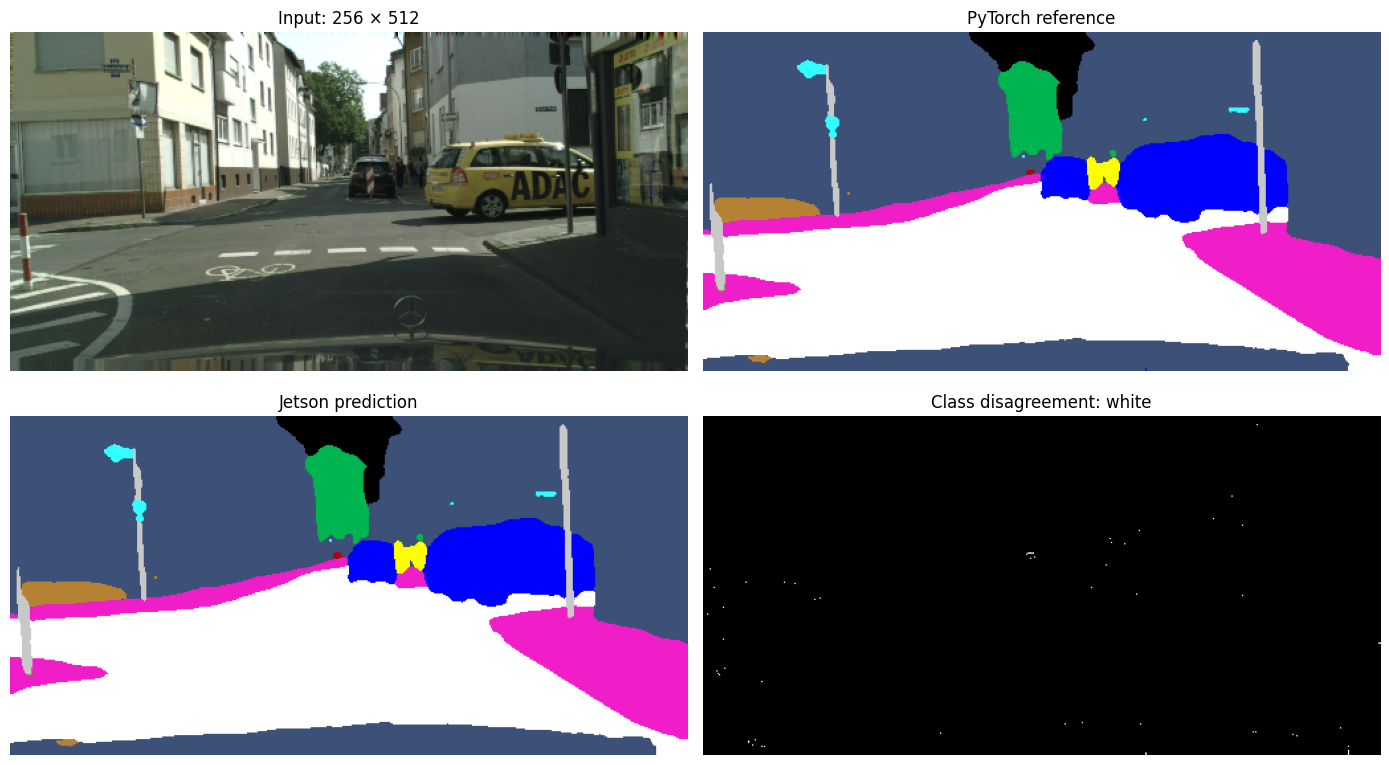

FIGURE_SAVED /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS/Results_Export/jetson_deployment/phase11_real_image_20260930T163549_520233Z/pytorch_vs_jetson_segmentation.png
SEMANTIC_COMPARISON_COMPLETE


In [6]:
from pathlib import Path
import hashlib
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

folder = Path(
    "/home/hrusikesh-nishank/Pictures/"
    "SwinSmall_Mask2Former_SGDW_PixelDecoder_CS/Results_Export/"
    "jetson_deployment/phase11_real_image_20260930T163549_520233Z"
)

def sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

reference_path = folder / "pytorch_reference.npz"
jetson_path = folder / "jetson_road_logits.npz"
assert jetson_path.is_file(), "Copy jetson_road_logits.npz here first."

# Both predictions use this same CPU postprocessing.
def semantic_prediction(saved):
    masks = torch.from_numpy(saved["masks_queries_logits"].copy()).float()
    classes = torch.from_numpy(saved["class_queries_logits"].copy()).float()
    assert torch.isfinite(masks).all()
    assert torch.isfinite(classes).all()

    with torch.no_grad():
        masks_up = F.interpolate(
            masks, size=(256, 512),
            mode="bilinear", align_corners=False
        )
        probabilities = classes.softmax(dim=-1)[..., :-1]
        scores = torch.einsum(
            "bqc,bqhw->bchw", probabilities, masks_up.sigmoid()
        )
        return scores.argmax(dim=1)[0].numpy().astype(np.uint8)

with np.load(str(reference_path), allow_pickle=False) as reference:
    pytorch_prediction = semantic_prediction(reference)
    original_prediction = reference["semantic_train_ids"].copy()

with np.load(str(jetson_path), allow_pickle=False) as deployed:
    assert str(deployed["input_file_sha256"].item()) == sha256(
        folder / "road_input.npz"
    ), "Input file mismatch"
    assert str(deployed["reference_file_sha256"].item()) == sha256(
        reference_path
    ), "Reference file mismatch"
    jetson_prediction = semantic_prediction(deployed)

class_names = [
    "road", "sidewalk", "building", "wall", "fence", "pole",
    "traffic light", "traffic sign", "vegetation", "terrain",
    "sky", "person", "rider", "car", "truck", "bus", "train",
    "motorcycle", "bicycle",
]

difference = pytorch_prediction != jetson_prediction
agreement = 100.0 * np.mean(~difference)

print("INPUT_AND_REFERENCE_HASH_PASS")
print(
    "PYTORCH_CPU_VS_SAVED_POSTPROCESS_AGREEMENT_PERCENT",
    100.0 * np.mean(pytorch_prediction == original_prediction)
)
print("PYTORCH_VS_JETSON_PIXEL_AGREEMENT_PERCENT", agreement)
print("DISAGREEING_PIXELS", int(difference.sum()), "OF", difference.size)
print("\nCLASS | PYTORCH_PIXELS | JETSON_PIXELS | AGREEMENT_IOU")

ious = []
for index, name in enumerate(class_names):
    reference_mask = pytorch_prediction == index
    deployed_mask = jetson_prediction == index
    union = np.count_nonzero(reference_mask | deployed_mask)
    if union == 0:
        continue
    intersection = np.count_nonzero(reference_mask & deployed_mask)
    iou = intersection / union
    ious.append(iou)
    print(
        "{} | {} | {} | {:.6f}".format(
            name, int(reference_mask.sum()),
            int(deployed_mask.sum()), iou
        )
    )

print("MEAN_PRESENT_CLASS_AGREEMENT_IOU", float(np.mean(ious)))
print("These compare predictions with each other, not with ground truth.")

# Use the notebook's high-contrast class palette for both predictions.
palette = np.array([
    [255,255,255], [240,30,200], [60,80,120], [130,90,60],
    [180,130,50], [200,200,200], [255,50,50], [50,255,255],
    [0,180,80], [120,160,40], [0,0,0], [255,255,0],
    [255,160,0], [0,0,255], [0,0,130], [0,120,255],
    [100,0,100], [0,150,150], [180,0,0],
], dtype=np.uint8)

rgb = np.array(Image.open(folder / "road_rgb_256x512.png").convert("RGB"))
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
panels = [
    (rgb, "Input: 256 × 512"),
    (palette[pytorch_prediction], "PyTorch reference"),
    (palette[jetson_prediction], "Jetson prediction"),
    (difference.astype(np.uint8) * 255, "Class disagreement: white"),
]
for axis, (picture, title) in zip(axes.flat, panels):
    if picture.ndim == 2:
        axis.imshow(picture, cmap="gray", vmin=0, vmax=255)
    else:
        axis.imshow(picture)
    axis.set_title(title)
    axis.axis("off")

fig.tight_layout()
figure_path = folder / "pytorch_vs_jetson_segmentation.png"
fig.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()

print("FIGURE_SAVED", figure_path)
print("SEMANTIC_COMPARISON_COMPLETE")